In [ ]:

# ==========================================
# AUDIT AWAL DATASET CLUSTERING SMARTBIN
# ==========================================

import os
import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

# 1. Upload file ZIP dari laptop
print("Silakan pilih file ZIP dataset kamu.")
uploaded = files.upload()

# 2. Ambil nama file ZIP yang diunggah
zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("File ZIP tidak ditemukan. Silakan upload file .zip.")

zip_path = os.path.join("/content", zip_files[0])
extract_path = "/content/SensorData"

# 3. Ekstrak file ZIP
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\nDataset berhasil diekstrak!")

# 4. Cari semua file CSV
csv_files = []

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

print("Jumlah file CSV:", len(csv_files))

if not csv_files:
    raise ValueError("Tidak ditemukan file CSV di dalam ZIP.")

# 5. Tampilkan contoh struktur CSV
print("\n=== CONTOH STRUKTUR DATASET ===")

for path in csv_files[:3]:
    print("\nNama file:", os.path.basename(path))

    try:
        df = pd.read_csv(path, nrows=5)
        print("Kolom:", df.columns.tolist())
        display(df.head())
    except Exception as e:
        print("File belum dapat dibaca:", e)

print("\n=== AUDIT AWAL SELESAI ===")


Silakan pilih file ZIP dataset kamu.


Saving SensorData(2).zip to SensorData(2).zip

Dataset berhasil diekstrak!
Jumlah file CSV: 1938

=== CONTOH STRUKTUR DATASET ===

Nama file: Container_24584_recs_UnCorrected_with_metrics_.csv
Kolom: ['Date', 'End_Pointer', 'Avg_Dist', 'Spearman']


,Date,End_Pointer,Avg_Dist,Spearman
0,2023-07-05 16:18:23.892,0,100.000000,69.631062
1,2023-07-12 20:20:11.561,10,16.857143,-69.335719
2,2023-08-03 20:51:50.125,38,99.647059,98.269653
3,2023-08-16 17:28:58.845,55,93.300000,93.854231
4,2023-08-28 21:01:17.697,75,64.750000,69.291197



Nama file: Container_11859_fill_UnCorrected_with_metrics_.csv
Kolom: ['Date', 'Fill', 'Rec', 'Cidx', 'Max', 'Min', 'Mean']


,Date,Fill,Rec,Cidx,Max,Min,Mean
0,2021-01-01 20:18:00,0,0,NaN,NaN,NaN,NaN
1,2021-01-02 16:16:00,12,0,NaN,NaN,NaN,NaN
2,2021-01-02 17:48:00,7,0,NaN,NaN,NaN,NaN
3,2021-01-02 20:53:00,0,0,NaN,NaN,NaN,NaN
4,2021-01-03 21:26:00,0,0,NaN,NaN,NaN,NaN



Nama file: Container_11811_fill_UnCorrected_with_metrics_.csv
Kolom: ['Date', 'Fill', 'Rec', 'Cidx', 'Max', 'Min', 'Mean']


,Date,Fill,Rec,Cidx,Max,Min,Mean
0,2021-01-01 09:01:00,7,0,NaN,NaN,NaN,NaN
1,2021-01-02 09:15:00,11,0,NaN,NaN,NaN,NaN
2,2021-01-03 09:30:00,11,0,NaN,NaN,NaN,NaN
3,2021-01-04 06:43:00,20,0,NaN,NaN,NaN,NaN
4,2021-01-04 09:15:00,11,0,NaN,NaN,NaN,NaN



=== AUDIT AWAL SELESAI ===


In [ ]:

import os
import pandas as pd

# Cari satu file CSV yang namanya mengandung "_fill"
fill_files = []

for root, dirs, filenames in os.walk("/content/SensorData"):
    for filename in filenames:
        if "_fill" in filename.lower() and filename.lower().endswith(".csv"):
            fill_files.append(os.path.join(root, filename))

# Pilih satu file sebagai sampel
sample_path = fill_files[0]
df = pd.read_csv(sample_path)

print("Nama file:", os.path.basename(sample_path))
print("Jumlah baris:", len(df))
print("\nJumlah nilai kosong:")
print(df.isna().sum())

print("\nStatistik kolom Fill:")
print(df["Fill"].describe())


Nama file: Container_11859_fill_UnCorrected_with_metrics_.csv
Jumlah baris: 2032

Jumlah nilai kosong:
Date     0
Fill     0
Rec      0
Cidx    29
Max     29
Min     29
Mean    29
dtype: int64

Statistik kolom Fill:
count    2032.000000
mean       36.519685
std        28.012352
min         0.000000
25%         9.000000
50%        33.000000
75%        59.000000
max       100.000000
Name: Fill, dtype: float64


In [ ]:

# Periksa urutan dan interval waktu pengamatan

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.sort_values("Date")

print("Waktu pengamatan pertama:")
print(df["Date"].min())

print("\nWaktu pengamatan terakhir:")
print(df["Date"].max())

print("\nJumlah tanggal yang tidak terbaca:")
print(df["Date"].isna().sum())

print("\nSelisih waktu antar-pengamatan:")
print(df["Date"].diff().describe())

print("\nContoh 10 pengamatan pertama:")
display(df[["Date", "Fill"]].head(10))


Waktu pengamatan pertama:
2021-01-01 20:18:00

Waktu pengamatan terakhir:
2023-10-20 17:13:00

Jumlah tanggal yang tidak terbaca:
0

Selisih waktu antar-pengamatan:
count                         2031
mean     0 days 12:04:31.048744460
std      0 days 09:27:55.605535975
min                0 days 00:31:00
25%                0 days 03:02:00
50%                0 days 09:06:00
75%                1 days 00:13:00
max                2 days 20:21:00
Name: Date, dtype: object

Contoh 10 pengamatan pertama:


,Date,Fill
0,2021-01-01 20:18:00,0
1,2021-01-02 16:16:00,12
2,2021-01-02 17:48:00,7
3,2021-01-02 20:53:00,0
4,2021-01-03 21:26:00,0
5,2021-01-04 22:00:00,0
6,2021-01-05 22:33:00,0
7,2021-01-06 23:06:00,0
8,2021-01-07 14:57:00,17
9,2021-01-07 15:59:00,3


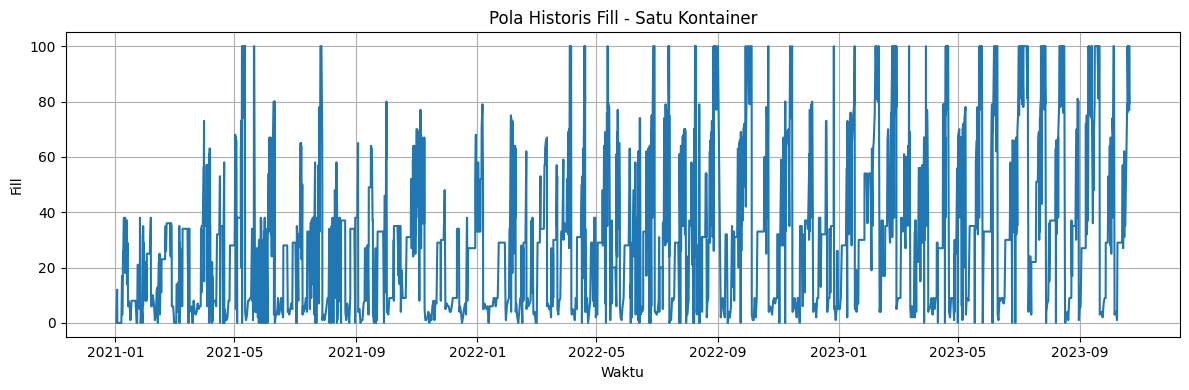

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(df["Date"], df["Fill"])
plt.title("Pola Historis Fill - Satu Kontainer")
plt.xlabel("Waktu")
plt.ylabel("Fill")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

total = len(df)
jumlah_penuh = (df["Fill"] >= 100).sum()
jumlah_nol = (df["Fill"] == 0).sum()

print("Total pengamatan:", total)
print("Pengamatan dengan Fill >= 100:", jumlah_penuh)
print("Pengamatan dengan Fill = 0:", jumlah_nol)
print("Persentase Fill >= 100:", round(jumlah_penuh / total * 100, 2), "%")
print("Persentase Fill = 0:", round(jumlah_nol / total * 100, 2), "%")


Total pengamatan: 2032
Pengamatan dengan Fill >= 100: 123
Pengamatan dengan Fill = 0: 91
Persentase Fill >= 100: 6.05 %
Persentase Fill = 0: 4.48 %


In [ ]:

# Hitung jumlah baris dan rentang waktu setiap file fill

import os
import pandas as pd

hasil = []

for path in fill_files:
    data = pd.read_csv(path, usecols=["Date", "Fill"])

    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    data["Fill"] = pd.to_numeric(data["Fill"], errors="coerce")

    hasil.append({
        "File": os.path.basename(path),
        "Jumlah_Data": len(data),
        "Tanggal_Awal": data["Date"].min(),
        "Tanggal_Akhir": data["Date"].max(),
        "Fill_Kosong": data["Fill"].isna().sum()
    })

ringkasan = pd.DataFrame(hasil)

print("Jumlah file fill:", len(ringkasan))
print("\nRingkasan dataset:")
display(ringkasan.head(10))

print("\nStatistik jumlah data per kontainer:")
display(ringkasan["Jumlah_Data"].describe())


Jumlah file fill: 968

Ringkasan dataset:


,File,Jumlah_Data,Tanggal_Awal,Tanggal_Akhir,Fill_Kosong
0,Container_11859_fill_UnCorrected_with_metrics_...,2032,2021-01-01 20:18:00,2023-10-20 17:13:00,0
1,Container_11811_fill_UnCorrected_with_metrics_...,1660,2021-01-01 09:01:00,2023-10-09 12:57:00,0
2,Container_13578_fill_UnCorrected_with_metrics_...,1879,2021-01-01 08:37:00,2023-10-05 13:19:00,0
3,Container_1610_fill_Corrected_with_metrics.csv,1393,2021-01-01 13:23:00,2023-10-20 15:07:00,0
4,Container_10150_fill_Corrected_with_metrics.csv,1592,2021-01-01 06:57:00,2023-10-12 13:20:00,0
5,Container_10561_fill_UnCorrected_with_metrics_...,1310,2021-01-01 09:52:00,2023-10-23 05:06:00,0
6,Container_11986_fill_Corrected_with_metrics.csv,1603,2021-01-01 15:38:00,2023-10-18 13:53:00,0
7,Container_5752_fill_Corrected_with_metrics.csv,1898,2021-01-01 09:48:00,2023-10-18 16:34:00,0
8,Container_11796_fill_Corrected_with_metrics.csv,1361,2021-01-01 16:52:00,2023-09-20 10:11:00,0
9,Container_3419_fill_Corrected_with_metrics.csv,1520,2021-01-01 18:50:00,2023-10-04 22:34:00,0



Statistik jumlah data per kontainer:


,Jumlah_Data
count,968.000000
mean,1671.094008
std,636.945531
min,154.000000
25%,1336.000000
50%,1591.500000
75%,1889.000000
max,7505.000000


In [ ]:

# Pemeriksaan nilai Fill pada seluruh kontainer

hasil_fill = []

for path in fill_files:
    data = pd.read_csv(path, usecols=["Fill"])
    fill = pd.to_numeric(data["Fill"], errors="coerce").dropna()

    hasil_fill.append({
        "File": os.path.basename(path),
        "Jumlah_Data": len(data),
        "Minimum_Fill": fill.min(),
        "Maksimum_Fill": fill.max(),
        "Jumlah_di_bawah_0": (fill < 0).sum(),
        "Jumlah_di_atas_100": (fill > 100).sum()
    })

kualitas_fill = pd.DataFrame(hasil_fill)

print("Ringkasan rentang nilai Fill:")
display(kualitas_fill[
    ["Minimum_Fill", "Maksimum_Fill",
     "Jumlah_di_bawah_0", "Jumlah_di_atas_100"]
].describe())

print("\nContoh kontainer dengan nilai di luar 0–100:")
display(
    kualitas_fill[
        (kualitas_fill["Jumlah_di_bawah_0"] > 0) |
        (kualitas_fill["Jumlah_di_atas_100"] > 0)
    ].head(10)
)

print("\nJumlah kontainer yang memiliki nilai di luar 0–100:",
      ((kualitas_fill["Jumlah_di_bawah_0"] > 0) |
       (kualitas_fill["Jumlah_di_atas_100"] > 0)).sum())


Ringkasan rentang nilai Fill:


,Minimum_Fill,Maksimum_Fill,Jumlah_di_bawah_0,Jumlah_di_atas_100
count,968.000000,968.000000,968.0,968.0
mean,0.504132,99.877066,0.0,0.0
std,5.198240,1.710232,0.0,0.0
min,0.000000,75.000000,0.0,0.0
25%,0.000000,100.000000,0.0,0.0
50%,0.000000,100.000000,0.0,0.0
75%,0.000000,100.000000,0.0,0.0
max,81.000000,100.000000,0.0,0.0



Contoh kontainer dengan nilai di luar 0–100:


,File,Jumlah_Data,Minimum_Fill,Maksimum_Fill,Jumlah_di_bawah_0,Jumlah_di_atas_100



Jumlah kontainer yang memiliki nilai di luar 0–100: 0


In [ ]:

# Hitung jenis file berdasarkan nama file

jumlah_corrected = sum(
    "uncorrected" not in os.path.basename(path).lower()
    and "corrected" in os.path.basename(path).lower()
    for path in fill_files
)

jumlah_uncorrected = sum(
    "uncorrected" in os.path.basename(path).lower()
    for path in fill_files
)

print("Jumlah file Corrected:", jumlah_corrected)
print("Jumlah file UnCorrected:", jumlah_uncorrected)
print("Total file:", len(fill_files))


Jumlah file Corrected: 484
Jumlah file UnCorrected: 484
Total file: 968


In [ ]:

# Cari satu kontainer yang memiliki kedua versi file

import os
import re

def container_id(path):
    nama = os.path.basename(path)
    match = re.search(r"Container_(\d+)_fill", nama, re.IGNORECASE)
    return match.group(1) if match else None

corrected_map = {
    container_id(p): p
    for p in fill_files
    if "corrected" in os.path.basename(p).lower()
    and "uncorrected" not in os.path.basename(p).lower()
}

uncorrected_map = {
    container_id(p): p
    for p in fill_files
    if "uncorrected" in os.path.basename(p).lower()
}

id_bersama = sorted(
    set(corrected_map) & set(uncorrected_map),
    key=lambda x: int(x) if x else -1
)

print("Jumlah ID kontainer yang ditemukan pada kedua versi:",
      len(id_bersama))

if id_bersama:
    cid = id_bersama[0]
    print("Contoh ID kontainer:", cid)
    print("Corrected:", os.path.basename(corrected_map[cid]))
    print("UnCorrected:", os.path.basename(uncorrected_map[cid]))
else:
    print("Belum ditemukan pasangan berdasarkan ID nama file.")


Jumlah ID kontainer yang ditemukan pada kedua versi: 484
Contoh ID kontainer: 192
Corrected: Container_192_fill_Corrected_with_metrics.csv
UnCorrected: Container_192_fill_UnCorrected_with_metrics_.csv


In [ ]:

# Bandingkan nilai Fill pada kontainer yang sama

cid = id_bersama[0]

df_corrected = pd.read_csv(corrected_map[cid])
df_uncorrected = pd.read_csv(uncorrected_map[cid])

print("ID kontainer:", cid)
print("Jumlah baris Corrected:", len(df_corrected))
print("Jumlah baris UnCorrected:", len(df_uncorrected))

print("\nStatistik Fill - Corrected")
print(df_corrected["Fill"].describe())

print("\nStatistik Fill - UnCorrected")
print(df_uncorrected["Fill"].describe())


ID kontainer: 192
Jumlah baris Corrected: 1238
Jumlah baris UnCorrected: 1238

Statistik Fill - Corrected
count    1238.000000
mean       35.245557
std        21.885447
min         0.000000
25%        22.000000
50%        33.000000
75%        46.000000
max       100.000000
Name: Fill, dtype: float64

Statistik Fill - UnCorrected
count    1238.000000
mean       35.245557
std        21.885447
min         0.000000
25%        22.000000
50%        33.000000
75%        46.000000
max       100.000000
Name: Fill, dtype: float64


In [ ]:

# Bandingkan nilai Fill pada semua pasangan kontainer

hasil_perbandingan = []

for cid in id_bersama:
    corrected = pd.read_csv(corrected_map[cid], usecols=["Fill"])
    uncorrected = pd.read_csv(uncorrected_map[cid], usecols=["Fill"])

    sama_panjang = len(corrected) == len(uncorrected)

    sama_fill = (
        sama_panjang
        and corrected["Fill"].equals(uncorrected["Fill"])
    )

    hasil_perbandingan.append({
        "Container_ID": cid,
        "Jumlah_Corrected": len(corrected),
        "Jumlah_UnCorrected": len(uncorrected),
        "Fill_Sama": sama_fill
    })

perbandingan = pd.DataFrame(hasil_perbandingan)

print("Total pasangan:", len(perbandingan))
print("Pasangan dengan Fill sama:", perbandingan["Fill_Sama"].sum())
print("Pasangan dengan Fill berbeda:", (~perbandingan["Fill_Sama"]).sum())

print("\nContoh pasangan yang berbeda:")
display(perbandingan[~perbandingan["Fill_Sama"]].head(10))


Total pasangan: 484
Pasangan dengan Fill sama: 432
Pasangan dengan Fill berbeda: 52

Contoh pasangan yang berbeda:


,Container_ID,Jumlah_Corrected,Jumlah_UnCorrected,Fill_Sama
22,1116,1013,1689,False
23,1137,1462,2954,False
24,1170,1909,3162,False
33,1399,3977,6835,False
35,1430,360,2129,False
38,1496,1537,1938,False
43,1655,1183,1939,False
52,1866,1482,3092,False
58,2471,2015,2310,False
59,2503,1461,1708,False


In [ ]:

cid = "1116"

df_c = pd.read_csv(corrected_map[cid])
df_u = pd.read_csv(uncorrected_map[cid])

for nama, df in [("Corrected", df_c), ("UnCorrected", df_u)]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    print(f"\n=== {nama} ===")
    print("Jumlah baris:", len(df))
    print("Tanggal awal:", df["Date"].min())
    print("Tanggal akhir:", df["Date"].max())
    print("Tanggal kosong:", df["Date"].isna().sum())
    print("Fill kosong:", df["Fill"].isna().sum())
    print("Statistik Fill:")
    print(df["Fill"].describe())



=== Corrected ===
Jumlah baris: 1013
Tanggal awal: 2021-12-28 19:38:00
Tanggal akhir: 2023-10-03 09:45:00
Tanggal kosong: 0
Fill kosong: 0
Statistik Fill:
count    1013.000000
mean       34.302073
std        26.377084
min         0.000000
25%         9.000000
50%        32.000000
75%        48.000000
max       100.000000
Name: Fill, dtype: float64

=== UnCorrected ===
Jumlah baris: 1689
Tanggal awal: 2021-01-01 02:01:00
Tanggal akhir: 2023-10-03 09:45:00
Tanggal kosong: 0
Fill kosong: 0
Statistik Fill:
count    1689.000000
mean       38.124334
std        29.883997
min         0.000000
25%        11.000000
50%        33.000000
75%        59.000000
max       100.000000
Name: Fill, dtype: float64


In [ ]:

# Bandingkan kedua versi pada rentang tanggal yang sama

awal = max(df_c["Date"].min(), df_u["Date"].min())
akhir = min(df_c["Date"].max(), df_u["Date"].max())

c_periode = df_c[df_c["Date"].between(awal, akhir)]
u_periode = df_u[df_u["Date"].between(awal, akhir)]

print("Rentang perbandingan:", awal, "sampai", akhir)

for nama, df in [
    ("Corrected", c_periode),
    ("UnCorrected", u_periode)
]:
    print(f"\n=== {nama} ===")
    print("Jumlah baris:", len(df))
    print("Rata-rata Fill:", round(df["Fill"].mean(), 2))
    print("Median Fill:", round(df["Fill"].median(), 2))
    print("Standar deviasi Fill:", round(df["Fill"].std(), 2))


Rentang perbandingan: 2021-12-28 19:38:00 sampai 2023-10-03 09:45:00

=== Corrected ===
Jumlah baris: 1013
Rata-rata Fill: 34.3
Median Fill: 32.0
Standar deviasi Fill: 26.38

=== UnCorrected ===
Jumlah baris: 1013
Rata-rata Fill: 34.3
Median Fill: 32.0
Standar deviasi Fill: 26.38


In [ ]:

# Bandingkan nilai Fill berdasarkan tanggal dan waktu

c = c_periode[["Date", "Fill"]].copy()
u = u_periode[["Date", "Fill"]].copy()

per_tanggal = c.merge(
    u,
    on="Date",
    how="outer",
    suffixes=("_Corrected", "_UnCorrected"),
    indicator=True
)

print("Total baris hasil pencocokan:", len(per_tanggal))
print("Tanggal yang ada di kedua versi:",
      (per_tanggal["_merge"] == "both").sum())
print("Tanggal hanya di Corrected:",
      (per_tanggal["_merge"] == "left_only").sum())
print("Tanggal hanya di UnCorrected:",
      (per_tanggal["_merge"] == "right_only").sum())

cocok = per_tanggal[
    (per_tanggal["_merge"] == "both")
    & (per_tanggal["Fill_Corrected"] == per_tanggal["Fill_UnCorrected"])
]

print("Tanggal dengan nilai Fill sama:", len(cocok))


Total baris hasil pencocokan: 1013
Tanggal yang ada di kedua versi: 1013
Tanggal hanya di Corrected: 0
Tanggal hanya di UnCorrected: 0
Tanggal dengan nilai Fill sama: 1013


In [ ]:

# Periksa kesamaan Fill berdasarkan tanggal pada semua pasangan

hasil = []

for cid in id_bersama:
    c = pd.read_csv(corrected_map[cid], usecols=["Date", "Fill"])
    u = pd.read_csv(uncorrected_map[cid], usecols=["Date", "Fill"])

    c["Date"] = pd.to_datetime(c["Date"], errors="coerce")
    u["Date"] = pd.to_datetime(u["Date"], errors="coerce")

    gabung = c.merge(
        u,
        on="Date",
        how="inner",
        suffixes=("_C", "_U")
    )

    sama = gabung["Fill_C"].eq(gabung["Fill_U"])

    hasil.append({
        "Container_ID": cid,
        "Baris_Corrected": len(c),
        "Baris_UnCorrected": len(u),
        "Tanggal_Cocok": len(gabung),
        "Fill_Sama": int(sama.sum()),
        "Fill_Berbeda": int((~sama).sum())
    })

hasil_semua = pd.DataFrame(hasil)

print("Jumlah kontainer:", len(hasil_semua))
print("Kontainer dengan semua Fill cocok pada tanggal yang sama:",
      (
          hasil_semua["Tanggal_Cocok"].eq(hasil_semua["Baris_Corrected"])
          & hasil_semua["Tanggal_Cocok"].eq(hasil_semua["Fill_Sama"])
      ).sum())
print("Total tanggal cocok:", hasil_semua["Tanggal_Cocok"].sum())
print("Total nilai Fill berbeda:", hasil_semua["Fill_Berbeda"].sum())


Jumlah kontainer: 484
Kontainer dengan semua Fill cocok pada tanggal yang sama: 479
Total tanggal cocok: 788605
Total nilai Fill berbeda: 10


In [ ]:

# Tampilkan pasangan kontainer yang masih perlu diperiksa

perlu_diperiksa = hasil_semua[
    (hasil_semua["Tanggal_Cocok"] != hasil_semua["Baris_Corrected"])
    | (hasil_semua["Tanggal_Cocok"] != hasil_semua["Baris_UnCorrected"])
    | (hasil_semua["Fill_Berbeda"] > 0)
]

display(
    perlu_diperiksa.sort_values(
        "Fill_Berbeda",
        ascending=False
    )
)


,Container_ID,Baris_Corrected,Baris_UnCorrected,Tanggal_Cocok,Fill_Sama,Fill_Berbeda
83,3292,2226,2226,2228,2226,2
91,5642,1413,1413,1415,1413,2
99,5931,2059,2059,2061,2059,2
388,12696,1933,1933,1935,1933,2
232,10167,1883,1883,1885,1883,2
38,1496,1537,1938,1537,1537,0
24,1170,1909,3162,1909,1909,0
23,1137,1462,2954,1462,1462,0
35,1430,360,2129,360,360,0
58,2471,2015,2310,2015,2015,0


In [ ]:

# Periksa kontainer 83 dengan ID angka atau teks

cid = 83

# Cari key yang sesuai tanpa bergantung pada tipe ID
key_c = next((k for k in corrected_map if str(k) == str(cid)), None)
key_u = next((k for k in uncorrected_map if str(k) == str(cid)), None)

if key_c is None or key_u is None:
    print("ID kontainer tidak ditemukan.")
    print("Contoh key corrected:", list(corrected_map.keys())[:10])
    print("Contoh key uncorrected:", list(uncorrected_map.keys())[:10])
else:
    c = pd.read_csv(corrected_map[key_c], usecols=["Date", "Fill"])
    u = pd.read_csv(uncorrected_map[key_u], usecols=["Date", "Fill"])

    c["Date"] = pd.to_datetime(c["Date"], errors="coerce")
    u["Date"] = pd.to_datetime(u["Date"], errors="coerce")

    print("Corrected — jumlah baris:", len(c))
    print("UnCorrected — jumlah baris:", len(u))
    print("Tanggal duplikat Corrected:", c["Date"].duplicated().sum())
    print("Tanggal duplikat UnCorrected:", u["Date"].duplicated().sum())

    gabung = c.merge(
        u,
        on="Date",
        how="inner",
        suffixes=("_C", "_U")
    )

    print("Baris hasil pencocokan:", len(gabung))
    print("Nilai Fill sama:",
          gabung["Fill_C"].eq(gabung["Fill_U"]).sum())
    print("Nilai Fill berbeda:",
          gabung["Fill_C"].ne(gabung["Fill_U"]).sum())


ID kontainer tidak ditemukan.
Contoh key corrected: ['1610', '10150', '11986', '5752', '11796', '3419', '10090', '11779', '11854', '11563']
Contoh key uncorrected: ['11859', '11811', '13578', '10561', '2853', '5934', '10174', '18689', '6900', '10176']


In [ ]:

# Cari ID yang tersedia pada kedua versi dataset

id_tersedia = sorted(
    set(corrected_map.keys()) & set(uncorrected_map.keys()),
    key=lambda x: int(x)
)

print("Jumlah ID yang tersedia di kedua versi:", len(id_tersedia))
print("10 ID pertama:", id_tersedia[:10])

# Pilih ID pertama untuk pemeriksaan
cid = id_tersedia[0]
print("ID yang akan diperiksa:", cid)


Jumlah ID yang tersedia di kedua versi: 484
10 ID pertama: ['192', '197', '209', '211', '340', '470', '505', '629', '754', '787']
ID yang akan diperiksa: 192


In [ ]:

# Periksa kontainer 192

cid = "192"

c = pd.read_csv(corrected_map[cid], usecols=["Date", "Fill"])
u = pd.read_csv(uncorrected_map[cid], usecols=["Date", "Fill"])

for df in [c, u]:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Corrected — jumlah baris:", len(c))
print("UnCorrected — jumlah baris:", len(u))
print("Tanggal duplikat Corrected:", c["Date"].duplicated().sum())
print("Tanggal duplikat UnCorrected:", u["Date"].duplicated().sum())

gabung = c.merge(
    u,
    on="Date",
    how="inner",
    suffixes=("_C", "_U")
)

print("Baris hasil pencocokan:", len(gabung))
print("Nilai Fill sama:", gabung["Fill_C"].eq(gabung["Fill_U"]).sum())
print("Nilai Fill berbeda:", gabung["Fill_C"].ne(gabung["Fill_U"]).sum())


Corrected — jumlah baris: 1238
UnCorrected — jumlah baris: 1238
Tanggal duplikat Corrected: 0
Tanggal duplikat UnCorrected: 0
Baris hasil pencocokan: 1238
Nilai Fill sama: 1238
Nilai Fill berbeda: 0


In [ ]:

hasil_cek = []

for cid in id_tersedia:
    c = pd.read_csv(corrected_map[cid], usecols=["Date", "Fill"])
    u = pd.read_csv(uncorrected_map[cid], usecols=["Date", "Fill"])

    c["Date"] = pd.to_datetime(c["Date"], errors="coerce")
    u["Date"] = pd.to_datetime(u["Date"], errors="coerce")

    # Pastikan tanggal tidak duplikat sebelum pencocokan
    if c["Date"].duplicated().any() or u["Date"].duplicated().any():
        hasil_cek.append({
            "Container_ID": cid,
            "Tanggal_Cocok": 0,
            "Fill_Berbeda": -1,
            "Status": "Tanggal duplikat"
        })
        continue

    gabung = c.merge(
        u,
        on="Date",
        how="inner",
        suffixes=("_C", "_U"),
        validate="one_to_one"
    )

    beda = gabung["Fill_C"].ne(gabung["Fill_U"])

    hasil_cek.append({
        "Container_ID": cid,
        "Baris_Corrected": len(c),
        "Baris_UnCorrected": len(u),
        "Tanggal_Cocok": len(gabung),
        "Fill_Berbeda": int(beda.sum()),
        "Status": "Cocok semua" if (
            len(gabung) == len(c) == len(u) and not beda.any()
        ) else "Perlu diperiksa"
    })

cek_final = pd.DataFrame(hasil_cek)

print("Total kontainer:", len(cek_final))
print("\nRingkasan status:")
print(cek_final["Status"].value_counts())

print("\nKontainer yang perlu diperiksa:")
display(cek_final[cek_final["Status"] != "Cocok semua"])


Total kontainer: 484

Ringkasan status:
Status
Cocok semua         427
Perlu diperiksa      52
Tanggal duplikat      5
Name: count, dtype: int64

Kontainer yang perlu diperiksa:


,Container_ID,Baris_Corrected,Baris_UnCorrected,Tanggal_Cocok,Fill_Berbeda,Status
22,1116,1013.0,1689.0,1013,0,Perlu diperiksa
23,1137,1462.0,2954.0,1462,0,Perlu diperiksa
24,1170,1909.0,3162.0,1909,0,Perlu diperiksa
33,1399,3977.0,6835.0,3977,0,Perlu diperiksa
35,1430,360.0,2129.0,360,0,Perlu diperiksa
38,1496,1537.0,1938.0,1537,0,Perlu diperiksa
43,1655,1183.0,1939.0,1183,0,Perlu diperiksa
52,1866,1482.0,3092.0,1482,0,Perlu diperiksa
58,2471,2015.0,2310.0,2015,0,Perlu diperiksa
59,2503,1461.0,1708.0,1461,0,Perlu diperiksa


In [ ]:

# Ambil ID yang tersedia di kedua map
id_tersedia = sorted(
    set(corrected_map.keys()) & set(uncorrected_map.keys()),
    key=int
)

# Periksa hanya ID yang tersedia
hasil_duplikat = []

for cid in id_tersedia:
    for nama, peta in [
        ("Corrected", corrected_map),
        ("UnCorrected", uncorrected_map)
    ]:
        df = pd.read_csv(peta[cid], usecols=["Date"])
        tanggal = pd.to_datetime(df["Date"], errors="coerce")

        jumlah_duplikat = tanggal.duplicated().sum()

        if jumlah_duplikat > 0:
            hasil_duplikat.append({
                "Container_ID": cid,
                "Versi": nama,
                "Jumlah_Baris": len(df),
                "Tanggal_Duplikat": jumlah_duplikat
            })

display(pd.DataFrame(hasil_duplikat))


,Container_ID,Versi,Jumlah_Baris,Tanggal_Duplikat
0,3292,Corrected,2226,1
1,3292,UnCorrected,2226,1
2,5642,Corrected,1413,1
3,5642,UnCorrected,1413,1
4,5931,Corrected,2059,1
5,5931,UnCorrected,2059,1
6,10167,Corrected,1883,1
7,10167,UnCorrected,1883,1
8,12696,Corrected,1933,1
9,12696,UnCorrected,1933,1


In [ ]:

cid = "3292"

c = pd.read_csv(corrected_map[cid], usecols=["Date", "Fill"])
c["Date"] = pd.to_datetime(c["Date"], errors="coerce")

duplikat = c[c["Date"].duplicated(keep=False)].sort_values("Date")

print("Jumlah baris:", len(c))
print("Jumlah baris dengan tanggal duplikat:", len(duplikat))
display(duplikat)


Jumlah baris: 2226
Jumlah baris dengan tanggal duplikat: 2


,Date,Fill
1091,2022-05-08 11:55:00,28
1092,2022-05-08 11:55:00,9


In [ ]:

cid = "3292"

u = pd.read_csv(uncorrected_map[cid], usecols=["Date", "Fill"])
u["Date"] = pd.to_datetime(u["Date"], errors="coerce")

tanggal_cek = pd.Timestamp("2022-05-08 11:55:00")

print("Catatan pada versi UnCorrected:")
display(
    u.loc[u["Date"] == tanggal_cek]
)


Catatan pada versi UnCorrected:


,Date,Fill
1091,2022-05-08 11:55:00,28
1092,2022-05-08 11:55:00,9


In [ ]:

# Tampilkan semua catatan dengan tanggal duplikat
# pada lima kontainer yang teridentifikasi

id_duplikat = ["3292", "5642", "5931", "10167", "12696"]

for cid in id_duplikat:
    df = pd.read_csv(
        corrected_map[cid],
        usecols=["Date", "Fill"]
    )
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    duplikat = df[
        df["Date"].duplicated(keep=False)
    ].sort_values("Date")

    print(f"\n=== Container {cid} ===")
    display(duplikat)



=== Container 3292 ===


,Date,Fill
1091,2022-05-08 11:55:00,28
1092,2022-05-08 11:55:00,9



=== Container 5642 ===


,Date,Fill
650,2022-05-08 11:48:00,71
651,2022-05-08 11:48:00,52



=== Container 5931 ===


,Date,Fill
1097,2022-05-29 13:30:00,20
1098,2022-05-29 13:30:00,0



=== Container 10167 ===


,Date,Fill
1097,2022-08-21 11:36:00,0
1098,2022-08-21 11:36:00,32



=== Container 12696 ===


,Date,Fill
1653,2023-05-14 15:31:00,19
1654,2023-05-14 15:31:00,46


In [ ]:

# Hitung jumlah kontainer yang memiliki timestamp duplikat
# pada versi Corrected

jumlah_duplikat = []

for cid in corrected_map:
    df = pd.read_csv(
        corrected_map[cid],
        usecols=["Date"]
    )

    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    jumlah_duplikat.append({
        "Container_ID": cid,
        "Baris": len(df),
        "Tanggal_Duplikat": int(df["Date"].duplicated().sum())
    })

cek_timestamp = pd.DataFrame(jumlah_duplikat)

print("Total kontainer:", len(cek_timestamp))
print(
    "Kontainer dengan timestamp duplikat:",
    (cek_timestamp["Tanggal_Duplikat"] > 0).sum()
)
print(
    "Total baris timestamp duplikat:",
    cek_timestamp["Tanggal_Duplikat"].sum()
)


Total kontainer: 484
Kontainer dengan timestamp duplikat: 5
Total baris timestamp duplikat: 5


In [ ]:

# Periksa kelengkapan kolom utama seluruh kontainer Corrected

kolom_utama = ["Date", "Fill"]

hasil_missing = []

for cid, path in corrected_map.items():
    df = pd.read_csv(path, usecols=kolom_utama)

    hasil_missing.append({
        "Container_ID": cid,
        "Jumlah_Baris": len(df),
        "Date_Kosong": df["Date"].isna().sum(),
        "Fill_Kosong": df["Fill"].isna().sum()
    })

cek_missing = pd.DataFrame(hasil_missing)

print("Total kontainer:", len(cek_missing))
print("Total baris:", cek_missing["Jumlah_Baris"].sum())
print("Total Date kosong:", cek_missing["Date_Kosong"].sum())
print("Total Fill kosong:", cek_missing["Fill_Kosong"].sum())
print(
    "Kontainer dengan nilai kosong:",
    (
        (cek_missing["Date_Kosong"] > 0)
        | (cek_missing["Fill_Kosong"] > 0)
    ).sum()
)


Total kontainer: 484
Total baris: 788595
Total Date kosong: 0
Total Fill kosong: 0
Kontainer dengan nilai kosong: 0


In [ ]:

# Pemeriksaan urutan waktu pada seluruh file Corrected

hasil_waktu = []

for cid, path in corrected_map.items():
    df = pd.read_csv(path, usecols=["Date", "Fill"])
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    hasil_waktu.append({
        "Container_ID": cid,
        "Baris": len(df),
        "Waktu_Terurut": df["Date"].is_monotonic_increasing,
        "Timestamp_Duplikat": int(df["Date"].duplicated().sum())
    })

cek_waktu = pd.DataFrame(hasil_waktu)

print("Total kontainer:", len(cek_waktu))
print(
    "Kontainer dengan waktu tidak berurutan:",
    (~cek_waktu["Waktu_Terurut"]).sum()
)
print(
    "Kontainer dengan timestamp duplikat:",
    (cek_waktu["Timestamp_Duplikat"] > 0).sum()
)
print(
    "Total timestamp duplikat:",
    cek_waktu["Timestamp_Duplikat"].sum()
)


Total kontainer: 484
Kontainer dengan waktu tidak berurutan: 0
Kontainer dengan timestamp duplikat: 5
Total timestamp duplikat: 5


In [ ]:

# Ringkas perbedaan nilai Fill pada timestamp duplikat

id_duplikat = ["3292", "5642", "5931", "10167", "12696"]

for cid in id_duplikat:
    df = pd.read_csv(
        corrected_map[cid],
        usecols=["Date", "Fill"]
    )
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    duplikat = df[df["Date"].duplicated(keep=False)].sort_values("Date")

    print(f"\nContainer {cid}")
    display(duplikat)




Container 3292


,Date,Fill
1091,2022-05-08 11:55:00,28
1092,2022-05-08 11:55:00,9



Container 5642


,Date,Fill
650,2022-05-08 11:48:00,71
651,2022-05-08 11:48:00,52



Container 5931


,Date,Fill
1097,2022-05-29 13:30:00,20
1098,2022-05-29 13:30:00,0



Container 10167


,Date,Fill
1097,2022-08-21 11:36:00,0
1098,2022-08-21 11:36:00,32



Container 12696


,Date,Fill
1653,2023-05-14 15:31:00,19
1654,2023-05-14 15:31:00,46


In [ ]:

# Gabungkan seluruh data Corrected menjadi satu DataFrame
# tanpa mengubah atau menghapus baris

semua_data = []

for cid, path in corrected_map.items():
    df = pd.read_csv(path, usecols=["Date", "Fill"])
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df["Container_ID"] = str(cid)
    semua_data.append(df)

df_sensor = pd.concat(semua_data, ignore_index=True)

print("Total baris:", len(df_sensor))
print("Total kontainer:", df_sensor["Container_ID"].nunique())
print("Date kosong:", df_sensor["Date"].isna().sum())
print("Fill kosong:", df_sensor["Fill"].isna().sum())
print("Timestamp duplikat per kontainer:",
      df_sensor.duplicated(["Container_ID", "Date"]).sum())

display(df_sensor.head())


Total baris: 788595
Total kontainer: 484
Date kosong: 0
Fill kosong: 0
Timestamp duplikat per kontainer: 5


,Date,Fill,Container_ID
0,2021-01-01 13:23:00,15,1610
1,2021-01-01 16:28:00,0,1610
2,2021-01-01 19:02:00,15,1610
3,2021-01-02 11:25:00,8,1610
4,2021-01-02 13:28:00,13,1610


In [ ]:

# Membentuk fitur awal untuk setiap kontainer

fitur = (
    df_sensor.groupby("Container_ID")["Fill"]
    .agg(
        Rata_rata_Fill="mean",
        Std_Fill="std"
    )
    .reset_index()
)

persen_tinggi = (
    df_sensor.assign(Tinggi=df_sensor["Fill"] >= 80)
    .groupby("Container_ID")["Tinggi"]
    .mean()
    .mul(100)
    .rename("Persen_Fill_GE_80")
)

persen_rendah = (
    df_sensor.assign(Rendah=df_sensor["Fill"] <= 20)
    .groupby("Container_ID")["Rendah"]
    .mean()
    .mul(100)
    .rename("Persen_Fill_LE_20")
)

fitur = fitur.merge(persen_tinggi, on="Container_ID")
fitur = fitur.merge(persen_rendah, on="Container_ID")

print("Jumlah kontainer:", len(fitur))
print("Jumlah fitur:", len(fitur.columns) - 1)
display(fitur.head())


Jumlah kontainer: 484
Jumlah fitur: 4


,Container_ID,Rata_rata_Fill,Std_Fill,Persen_Fill_GE_80,Persen_Fill_LE_20
0,1000,48.921522,29.276038,16.689513,20.253598
1,10037,35.602376,22.340887,3.074773,29.909154
2,10073,23.229549,19.508623,1.168614,51.168614
3,10076,28.243051,23.935036,3.349964,42.765502
4,10077,27.507720,16.592090,0.908265,40.962761


In [ ]:

import numpy as np

kolom_fitur = [
    "Rata_rata_Fill",
    "Std_Fill",
    "Persen_Fill_GE_80",
    "Persen_Fill_LE_20"
]

print("Nilai tak hingga per fitur:")
print(
    np.isinf(fitur[kolom_fitur].to_numpy()).sum(axis=0)
)


Nilai tak hingga per fitur:
[0 0 0 0]


In [ ]:

from sklearn.preprocessing import StandardScaler

kolom_fitur = [
    "Rata_rata_Fill",
    "Std_Fill",
    "Persen_Fill_GE_80",
    "Persen_Fill_LE_20"
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(fitur[kolom_fitur])

print("Ukuran data setelah standardisasi:", X_scaled.shape)
print("Rata-rata setiap fitur:")
print(X_scaled.mean(axis=0).round(3))
print("Standar deviasi setiap fitur:")
print(X_scaled.std(axis=0).round(3))


Ukuran data setelah standardisasi: (484, 4)
Rata-rata setiap fitur:
[-0. -0.  0. -0.]
Standar deviasi setiap fitur:
[1. 1. 1. 1.]


Variansi yang dijelaskan dua komponen: 87.45 %


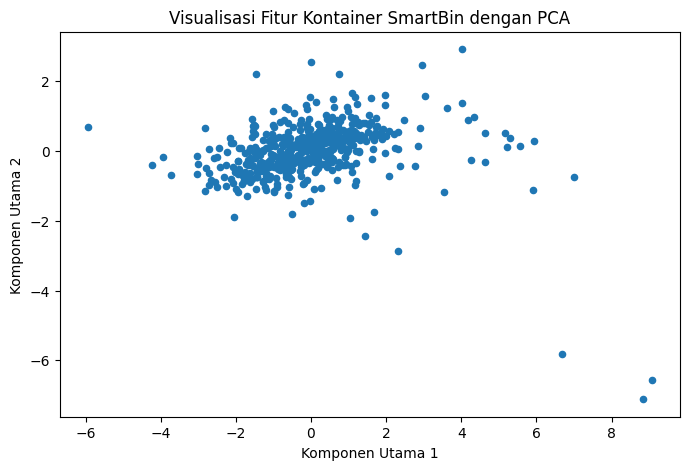

In [ ]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variansi yang dijelaskan dua komponen:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=20)
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.title("Visualisasi Fitur Kontainer SmartBin dengan PCA")
plt.show()


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hasil_kmeans = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    label = model.fit_predict(X_scaled)
    skor = silhouette_score(X_scaled, label)

    hasil_kmeans.append({
        "Jumlah_Cluster": k,
        "Silhouette_Score": round(skor, 4),
        "Inertia": round(model.inertia_, 2)
    })

df_kmeans = pd.DataFrame(hasil_kmeans)
display(df_kmeans)


,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.3833,1239.42
1,3,0.4129,800.24
2,4,0.4187,615.23
3,5,0.3373,484.03
4,6,0.3185,418.33
5,7,0.3190,360.04
6,8,0.2950,323.66


In [ ]:

# Membentuk model K-Means dengan 4 cluster

kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

fitur["Cluster_KMeans"] = kmeans_4.fit_predict(X_scaled)

print("Jumlah kontainer per cluster:")
print(
    fitur["Cluster_KMeans"]
    .value_counts()
    .sort_index()
)

print("\nRata-rata fitur pada setiap cluster:")
display(
    fitur.groupby("Cluster_KMeans")[kolom_fitur]
    .mean()
    .round(2)
)


Jumlah kontainer per cluster:
Cluster_KMeans
0    263
1    198
2     20
3      3
Name: count, dtype: int64

Rata-rata fitur pada setiap cluster:


,Rata_rata_Fill,Std_Fill,Persen_Fill_GE_80,Persen_Fill_LE_20
Cluster_KMeans,,,,
0,39.02,27.12,7.60,28.80
1,28.78,21.55,2.12,40.28
2,58.40,34.32,36.73,18.28
3,95.05,9.27,85.66,0.29


In [ ]:

# Identifikasi tiga kontainer di Cluster 3

kolom_tampil = [
    "Container_ID",
    "Rata_rata_Fill",
    "Std_Fill",
    "Persen_Fill_GE_80",
    "Persen_Fill_LE_20"
]

display(
    fitur.loc[
        fitur["Cluster_KMeans"] == 3,
        kolom_tampil
    ]
)


,Container_ID,Rata_rata_Fill,Std_Fill,Persen_Fill_GE_80,Persen_Fill_LE_20
270,16357,90.986239,10.380982,59.174312,0.000000
337,22005,95.756554,7.422070,100.000000,0.000000
413,6888,98.414097,10.009525,97.797357,0.881057


In [ ]:

# Tampilkan ulang data Cluster 3 dengan format yang jelas

kolom_tampil = [
    "Container_ID",
    "Rata_rata_Fill",
    "Std_Fill",
    "Persen_Fill_GE_80",
    "Persen_Fill_LE_20"
]

cluster3 = fitur.loc[
    fitur["Cluster_KMeans"] == 3,
    kolom_tampil
].copy()

print("Jumlah kontainer di Cluster 3:", len(cluster3))
print("Nama kolom:", cluster3.columns.tolist())

display(cluster3.to_string(index=False))


Jumlah kontainer di Cluster 3: 3
Nama kolom: ['Container_ID', 'Rata_rata_Fill', 'Std_Fill', 'Persen_Fill_GE_80', 'Persen_Fill_LE_20']


'Container_ID  Rata_rata_Fill  Std_Fill  Persen_Fill_GE_80  Persen_Fill_LE_20\n       16357       90.986239 10.380982          59.174312           0.000000\n       22005       95.756554  7.422070         100.000000           0.000000\n        6888       98.414097 10.009525          97.797357           0.881057'

In [ ]:

# Validasi ulang rentang nilai Fill

print("Fill di bawah 0:", (df_sensor["Fill"] < 0).sum())
print("Fill di atas 100:", (df_sensor["Fill"] > 100).sum())
print("Fill bukan angka:",
      pd.to_numeric(df_sensor["Fill"], errors="coerce").isna().sum())
print("Total baris:", len(df_sensor))


Fill di bawah 0: 0
Fill di atas 100: 0
Fill bukan angka: 0
Total baris: 788595


In [ ]:

# Periksa perubahan Fill antar-pengamatan berurutan

df_urut = df_sensor.sort_values(
    ["Container_ID", "Date"]
).copy()

grup = df_urut.groupby("Container_ID")

df_urut["Selisih_Fill"] = grup["Fill"].diff().abs()
df_urut["Selang_Jam"] = (
    grup["Date"].diff().dt.total_seconds() / 3600
)

lonjakan = df_urut[df_urut["Selisih_Fill"] >= 50].copy()

print("Jumlah perubahan Fill >= 50 poin:", len(lonjakan))
print("Jumlah kontainer yang mengalami perubahan tersebut:",
      lonjakan["Container_ID"].nunique())

display(
    lonjakan[
        [
            "Container_ID",
            "Date",
            "Fill",
            "Selisih_Fill",
            "Selang_Jam"
        ]
    ].head(10)
)


Jumlah perubahan Fill >= 50 poin: 34411
Jumlah kontainer yang mengalami perubahan tersebut: 482


,Container_ID,Date,Fill,Selisih_Fill,Selang_Jam
525244,1000,2021-01-16 11:30:00,100,100.0,166.850000
525245,1000,2021-01-16 12:28:00,40,60.0,0.966667
525251,1000,2021-01-20 18:27:00,100,60.0,5.533333
525259,1000,2021-01-29 11:45:00,44,56.0,22.100000
525263,1000,2021-01-30 12:53:00,5,51.0,13.066667
525264,1000,2021-01-30 13:23:00,58,53.0,0.500000
525273,1000,2021-02-01 20:11:00,0,100.0,3.016667
525317,1000,2021-02-12 14:04:00,71,54.0,0.516667
525322,1000,2021-02-12 23:10:00,0,72.0,1.016667
525348,1000,2021-02-20 12:08:00,1,99.0,19.566667


In [ ]:

# Cari perubahan Fill >= 50 poin dalam waktu <= 1 jam

lonjakan_singkat = df_urut[
    (df_urut["Selisih_Fill"] >= 50) &
    (df_urut["Selang_Jam"] <= 1)
].copy()

print("Jumlah perubahan besar dalam <= 1 jam:",
      len(lonjakan_singkat))

print("Jumlah kontainer yang mengalami:",
      lonjakan_singkat["Container_ID"].nunique())

display(
    lonjakan_singkat[
        [
            "Container_ID",
            "Date",
            "Fill",
            "Selisih_Fill",
            "Selang_Jam"
        ]
    ].head(15)
)


Jumlah perubahan besar dalam <= 1 jam: 2224
Jumlah kontainer yang mengalami: 368


,Container_ID,Date,Fill,Selisih_Fill,Selang_Jam
525245,1000,2021-01-16 12:28:00,40,60.0,0.966667
525264,1000,2021-01-30 13:23:00,58,53.0,0.500000
525317,1000,2021-02-12 14:04:00,71,54.0,0.516667
525496,1000,2021-04-06 18:53:00,100,56.0,1.000000
525597,1000,2021-05-11 19:30:00,100,56.0,1.000000
525651,1000,2021-06-01 19:09:00,0,100.0,1.000000
525781,1000,2021-07-23 19:16:00,0,68.0,1.000000
526102,1000,2021-11-11 21:49:00,0,100.0,1.000000
526296,1000,2022-01-18 22:16:00,0,67.0,1.000000
526653,1000,2022-05-31 21:55:00,0,80.0,1.000000


In [ ]:
# Memeriksa arah perubahan Fill yang besar

perubahan_besar = df_urut[
    (df_urut["Selisih_Fill"] >= 50) &
    (df_urut["Selang_Jam"] <= 1)
].copy()

# Hitung perubahan Fill bertanda
perubahan_besar["Perubahan_Fill"] = (
    perubahan_besar["Fill"] -
    perubahan_besar.groupby("Container_ID")["Fill"].shift(1)
)

print("Jumlah perubahan besar:",
      len(perubahan_besar))

print("\nJumlah kenaikan besar:",
      (perubahan_besar["Perubahan_Fill"] > 0).sum())

print("Jumlah penurunan besar:",
      (perubahan_besar["Perubahan_Fill"] < 0).sum())

print("\nContoh perubahan besar:")
display(
    perubahan_besar[
        ["Container_ID", "Date", "Fill",
         "Perubahan_Fill", "Selang_Jam"]
    ].head(10)
)

Jumlah perubahan besar: 2224

Jumlah kenaikan besar: 767
Jumlah penurunan besar: 791

Contoh perubahan besar:


,Container_ID,Date,Fill,Perubahan_Fill,Selang_Jam
525245,1000,2021-01-16 12:28:00,40,NaN,0.966667
525264,1000,2021-01-30 13:23:00,58,18.0,0.500000
525317,1000,2021-02-12 14:04:00,71,13.0,0.516667
525496,1000,2021-04-06 18:53:00,100,29.0,1.000000
525597,1000,2021-05-11 19:30:00,100,0.0,1.000000
525651,1000,2021-06-01 19:09:00,0,-100.0,1.000000
525781,1000,2021-07-23 19:16:00,0,0.0,1.000000
526102,1000,2021-11-11 21:49:00,0,0.0,1.000000
526296,1000,2022-01-18 22:16:00,0,0.0,1.000000
526653,1000,2022-05-31 21:55:00,0,0.0,1.000000


In [ ]:
# Urutkan data berdasarkan kontainer dan waktu
df_cek = df_sensor.sort_values(
    ["Container_ID", "Date"]
).copy()

# Hitung perubahan Fill dari pengukuran sebelumnya
df_cek["Perubahan_Fill"] = (
    df_cek.groupby("Container_ID")["Fill"].diff()
)

# Hitung selang waktu dalam jam
df_cek["Selang_Jam"] = (
    df_cek.groupby("Container_ID")["Date"]
    .diff()
    .dt.total_seconds() / 3600
)

# Ambil perubahan minimal 50 poin dalam <= 1 jam
mask = (
    (df_cek["Perubahan_Fill"].abs() >= 50) &
    (df_cek["Selang_Jam"] <= 1)
)

hasil_cek = df_cek[mask]

print("Total perubahan besar:", len(hasil_cek))
print("Kenaikan besar:",
      (hasil_cek["Perubahan_Fill"] >= 50).sum())
print("Penurunan besar:",
      (hasil_cek["Perubahan_Fill"] <= -50).sum())

print("Perubahan nol:",
      (hasil_cek["Perubahan_Fill"] == 0).sum())

Total perubahan besar: 2224
Kenaikan besar: 1136
Penurunan besar: 1088
Perubahan nol: 0


In [ ]:
# Periksa duplikasi waktu pada setiap kontainer
duplikat_waktu = df_sensor[
    df_sensor.duplicated(
        subset=["Container_ID", "Date"],
        keep=False
    )
].sort_values(["Container_ID", "Date"])

print("Jumlah baris dengan waktu duplikat:",
      len(duplikat_waktu))

print("Jumlah kontainer yang mengalami duplikasi:",
      duplikat_waktu["Container_ID"].nunique())

display(duplikat_waktu.head(20))

Jumlah baris dengan waktu duplikat: 10
Jumlah kontainer yang mengalami duplikasi: 5


,Date,Fill,Container_ID
290196,2022-08-21 11:36:00,0,10167
290197,2022-08-21 11:36:00,32,10167
398508,2023-05-14 15:31:00,19,12696
398509,2023-05-14 15:31:00,46,12696
69982,2022-05-08 11:55:00,28,3292
69983,2022-05-08 11:55:00,9,3292
342335,2022-05-08 11:48:00,71,5642
342336,2022-05-08 11:48:00,52,5642
74871,2022-05-29 13:30:00,20,5931
74872,2022-05-29 13:30:00,0,5931


In [ ]:
# Periksa data asli Container 10167
container_id = "10167"

print("File sumber:", corrected_map[container_id])

display(
    pd.read_csv(corrected_map[container_id])[
        ["Date", "Fill"]
    ].loc[
        lambda df: df["Date"].astype(str)
        .str.startswith("2022-08-21 11:36")
    ]
)

File sumber: /content/SensorData/Deliver_data/Container_10167_fill_Corrected_with_metrics.csv


,Date,Fill
1097,2022-08-21 11:36:00,0
1098,2022-08-21 11:36:00,32


In [ ]:
# Tampilkan seluruh pasangan waktu duplikat
display(
    duplikat_waktu[
        ["Container_ID", "Date", "Fill"]
    ].sort_values(
        ["Container_ID", "Date", "Fill"]
    ).reset_index(drop=True)
)

,Container_ID,Date,Fill
0,10167,2022-08-21 11:36:00,0
1,10167,2022-08-21 11:36:00,32
2,12696,2023-05-14 15:31:00,19
3,12696,2023-05-14 15:31:00,46
4,3292,2022-05-08 11:55:00,9
5,3292,2022-05-08 11:55:00,28
6,5642,2022-05-08 11:48:00,52
7,5642,2022-05-08 11:48:00,71
8,5931,2022-05-29 13:30:00,0
9,5931,2022-05-29 13:30:00,20


In [ ]:
# Salin data asli agar tidak berubah
df_bersih = df_sensor.copy()

# Gabungkan pengukuran dengan Container_ID dan Date yang sama
df_bersih = (
    df_bersih
    .groupby(["Container_ID", "Date"], as_index=False)
    .agg(Fill=("Fill", "mean"))
)

print("Jumlah baris sebelum:", len(df_sensor))
print("Jumlah baris sesudah:", len(df_bersih))

print(
    "Duplikasi timestamp tersisa:",
    df_bersih.duplicated(
        subset=["Container_ID", "Date"]
    ).sum()
)

Jumlah baris sebelum: 788595
Jumlah baris sesudah: 788590
Duplikasi timestamp tersisa: 0


In [ ]:
# Periksa kualitas data setelah penanganan duplikasi

print("Jumlah baris:", len(df_bersih))
print("Jumlah Container:", df_bersih["Container_ID"].nunique())

print("\nNilai kosong:")
print(df_bersih[["Container_ID", "Date", "Fill"]].isna().sum())

print("\nNilai Fill di bawah 0:",
      (df_bersih["Fill"] < 0).sum())

print("Nilai Fill di atas 100:",
      (df_bersih["Fill"] > 100).sum())

print("\nTipe data:")
print(df_bersih.dtypes)

print("\nStatistik Fill:")
print(df_bersih["Fill"].describe())

Jumlah baris: 788590
Jumlah Container: 484

Nilai kosong:
Container_ID    0
Date            0
Fill            0
dtype: int64

Nilai Fill di bawah 0: 0
Nilai Fill di atas 100: 0

Tipe data:
Container_ID            object
Date            datetime64[ns]
Fill                   float64
dtype: object

Statistik Fill:
count    788590.000000
mean         36.999316
std          27.496993
min           0.000000
25%          12.000000
50%          33.000000
75%          55.000000
max         100.000000
Name: Fill, dtype: float64


In [ ]:
# Periksa durasi dan jumlah pengamatan setiap kontainer

ringkasan_kontainer = (
    df_bersih.groupby("Container_ID")
    .agg(
        Jumlah_Pengamatan=("Fill", "size"),
        Mulai_Pengamatan=("Date", "min"),
        Akhir_Pengamatan=("Date", "max")
    )
)

ringkasan_kontainer["Durasi_Hari"] = (
    ringkasan_kontainer["Akhir_Pengamatan"]
    - ringkasan_kontainer["Mulai_Pengamatan"]
).dt.total_seconds() / 86400

print("Jumlah pengamatan per kontainer:")
print(ringkasan_kontainer["Jumlah_Pengamatan"].describe())

print("\nDurasi pengamatan (hari):")
print(ringkasan_kontainer["Durasi_Hari"].describe())

print("\n5 kontainer dengan pengamatan paling sedikit:")
display(
    ringkasan_kontainer
    .sort_values("Jumlah_Pengamatan")
    .head(5)
)

print("\n5 kontainer dengan durasi pengamatan terpendek:")
display(
    ringkasan_kontainer
    .sort_values("Durasi_Hari")
    .head(5)
)

Jumlah pengamatan per kontainer:
count     484.000000
mean     1629.318182
std       599.794773
min       154.000000
25%      1309.750000
50%      1554.500000
75%      1868.500000
max      4048.000000
Name: Jumlah_Pengamatan, dtype: float64

Durasi pengamatan (hari):
count     484.000000
mean      850.067410
std       308.692199
min        33.381944
25%       922.553646
50%      1007.745833
75%      1018.454340
max      1025.567361
Name: Durasi_Hari, dtype: float64

5 kontainer dengan pengamatan paling sedikit:


,Jumlah_Pengamatan,Mulai_Pengamatan,Akhir_Pengamatan,Durasi_Hari
Container_ID,,,,
13138,154,2023-07-12 21:16:00,2023-10-04 22:34:00,84.054167
24584,159,2023-07-06 09:45:00,2023-10-13 04:25:00,98.777778
20348,180,2023-06-12 19:50:00,2023-09-28 00:44:00,107.204167
16357,218,2023-07-15 02:28:00,2023-10-10 19:39:00,87.715972
6888,227,2023-07-15 00:17:00,2023-10-09 18:48:00,86.771528



5 kontainer dengan durasi pengamatan terpendek:


,Jumlah_Pengamatan,Mulai_Pengamatan,Akhir_Pengamatan,Durasi_Hari
Container_ID,,,,
11833,830,2023-09-07 06:35:00,2023-10-10 15:45:00,33.381944
7948,1089,2023-08-22 22:12:00,2023-10-06 17:32:00,44.805556
21918,1387,2023-08-02 18:03:00,2023-09-27 21:05:00,56.126389
1137,1462,2023-08-16 18:13:00,2023-10-13 18:26:00,58.009028
20390,1416,2023-08-22 22:14:00,2023-10-20 17:27:00,58.800694


In [ ]:
# Hitung jeda waktu antar-pengamatan setiap kontainer
df_jeda = df_bersih.sort_values(
    ["Container_ID", "Date"]
).copy()

df_jeda["Jeda_Jam"] = (
    df_jeda.groupby("Container_ID")["Date"]
    .diff()
    .dt.total_seconds() / 3600
)

jeda_valid = df_jeda["Jeda_Jam"].dropna()

print("Statistik jeda antar-pengamatan (jam):")
print(jeda_valid.describe())

print("\nJumlah jeda lebih dari 6 jam:",
      (jeda_valid > 6).sum())

print("Jumlah jeda lebih dari 24 jam:",
      (jeda_valid > 24).sum())

print("Jumlah jeda lebih dari 7 hari:",
      (jeda_valid > 168).sum())

print("\n5 kontainer dengan median jeda terbesar:")
display(
    df_jeda.groupby("Container_ID")["Jeda_Jam"]
    .median()
    .sort_values(ascending=False)
    .head(5)
)

Statistik jeda antar-pengamatan (jam):
count    788106.000000
mean         12.529258
std          16.432124
min           0.016667
25%           1.950000
50%          10.850000
75%          22.700000
max        3456.033333
Name: Jeda_Jam, dtype: float64

Jumlah jeda lebih dari 6 jam: 470470
Jumlah jeda lebih dari 24 jam: 118290
Jumlah jeda lebih dari 7 hari: 226

5 kontainer dengan median jeda terbesar:


,Jeda_Jam
Container_ID,
11778,24.816667
3317,24.800000
11808,24.800000
11026,24.750000
14325,24.733333


In [ ]:
# Hitung jumlah pengamatan per bulan
df_bersih["Bulan"] = df_bersih["Date"].dt.to_period("M")

pengamatan_bulanan = (
    df_bersih.groupby("Bulan")
    .size()
    .rename("Jumlah_Pengamatan")
    .reset_index()
)

display(pengamatan_bulanan)

print("Bulan dengan pengamatan paling sedikit:")
display(pengamatan_bulanan.nsmallest(5, "Jumlah_Pengamatan"))

print("Bulan dengan pengamatan paling banyak:")
display(pengamatan_bulanan.nlargest(5, "Jumlah_Pengamatan"))

,Bulan,Jumlah_Pengamatan
0,2021-01,21119
1,2021-02,20319
2,2021-03,19457
3,2021-04,17519
4,2021-05,18494
5,2021-06,18189
6,2021-07,19758
7,2021-08,19481
8,2021-09,18904
9,2021-10,18949


Bulan dengan pengamatan paling sedikit:


,Bulan,Jumlah_Pengamatan
13,2022-02,17371
3,2021-04,17519
10,2021-11,18077
5,2021-06,18189
22,2022-11,18483


Bulan dengan pengamatan paling banyak:


,Bulan,Jumlah_Pengamatan
31,2023-08,54622
30,2023-07,51397
32,2023-09,50734
29,2023-06,36863
28,2023-05,23539


In [ ]:
# Hitung jumlah pengamatan per kontainer per bulan
df_bersih["Bulan"] = df_bersih["Date"].dt.to_period("M")

pengamatan_kontainer_bulanan = (
    df_bersih.groupby(["Bulan", "Container_ID"])
    .size()
    .rename("Jumlah")
    .reset_index()
)

ringkasan_bulanan = (
    pengamatan_kontainer_bulanan.groupby("Bulan")
    .agg(
        Kontainer_Aktif=("Container_ID", "nunique"),
        Median_Pengamatan=("Jumlah", "median"),
        Rata_rata_Pengamatan=("Jumlah", "mean")
    )
    .reset_index()
)

display(ringkasan_bulanan)

,Bulan,Kontainer_Aktif,Median_Pengamatan,Rata_rata_Pengamatan
0,2021-01,356,56.0,59.323034
1,2021-02,361,53.0,56.285319
2,2021-03,365,50.0,53.306849
3,2021-04,367,45.0,47.735695
4,2021-05,368,46.0,50.255435
5,2021-06,376,46.0,48.375000
6,2021-07,378,49.5,52.269841
7,2021-08,381,49.0,51.131234
8,2021-09,382,47.0,49.486911
9,2021-10,385,47.0,49.218182


In [ ]:
# Periksa jumlah bulan pengamatan setiap kontainer

bulan_per_kontainer = (
    df_bersih.groupby("Container_ID")["Bulan"]
    .nunique()
)

print("Statistik jumlah bulan per kontainer:")
print(bulan_per_kontainer.describe())

print("\nJumlah kontainer berdasarkan cakupan bulan:")

for batas in [3, 6, 12, 24, 30]:
    jumlah = (bulan_per_kontainer >= batas).sum()
    print(f"{batas} bulan atau lebih: {jumlah} kontainer")

Statistik jumlah bulan per kontainer:
count    484.000000
mean      28.539256
std        9.975151
min        2.000000
25%       30.000000
50%       34.000000
75%       34.000000
max       34.000000
Name: Bulan, dtype: float64

Jumlah kontainer berdasarkan cakupan bulan:
3 bulan atau lebih: 482 kontainer
6 bulan atau lebih: 433 kontainer
12 bulan atau lebih: 424 kontainer
24 bulan atau lebih: 388 kontainer
30 bulan atau lebih: 365 kontainer


In [ ]:
# Periksa kontainer yang memiliki data pada setiap bulan tahun 2022

df_bersih["Bulan"] = df_bersih["Date"].dt.to_period("M")

bulan_2022 = [f"2022-{bulan:02d}" for bulan in range(1, 13)]

cakupan_2022 = (
    df_bersih[
        df_bersih["Bulan"].astype(str).isin(bulan_2022)
    ]
    .groupby("Container_ID")["Bulan"]
    .nunique()
)

print("Kontainer dengan data pada 12 bulan di 2022:",
      (cakupan_2022 == 12).sum())

print("Kontainer dengan data minimal 10 bulan di 2022:",
      (cakupan_2022 >= 10).sum())

print("Kontainer dengan data minimal 6 bulan di 2022:",
      (cakupan_2022 >= 6).sum())

Kontainer dengan data pada 12 bulan di 2022: 377
Kontainer dengan data minimal 10 bulan di 2022: 397
Kontainer dengan data minimal 6 bulan di 2022: 413


In [ ]:
# Ambil data Januari–Desember 2022
df_2022 = df_bersih[
    df_bersih["Date"].dt.year == 2022
].copy()

# Ringkas jumlah pengamatan setiap kontainer
ringkasan_2022 = (
    df_2022.groupby("Container_ID")
    .agg(
        Jumlah_Pengamatan=("Fill", "size"),
        Bulan_Aktif=("Bulan", "nunique"),
        Mulai=("Date", "min"),
        Akhir=("Date", "max")
    )
)

print("Statistik jumlah pengamatan selama 2022:")
print(ringkasan_2022["Jumlah_Pengamatan"].describe())

print("\nStatistik jumlah bulan aktif:")
print(ringkasan_2022["Bulan_Aktif"].describe())

print("\n5 kontainer dengan pengamatan paling sedikit:")
display(
    ringkasan_2022.sort_values("Jumlah_Pengamatan").head(5)
)

Statistik jumlah pengamatan selama 2022:
count     427.000000
mean      558.906323
std       159.240865
min        27.000000
25%       475.000000
50%       555.000000
75%       640.000000
max      1474.000000
Name: Jumlah_Pengamatan, dtype: float64

Statistik jumlah bulan aktif:
count    427.000000
mean      11.491803
std        1.754084
min        1.000000
25%       12.000000
50%       12.000000
75%       12.000000
max       12.000000
Name: Bulan_Aktif, dtype: float64

5 kontainer dengan pengamatan paling sedikit:


,Jumlah_Pengamatan,Bulan_Aktif,Mulai,Akhir
Container_ID,,,,
20862,27,2,2022-09-13 14:37:00,2022-10-14 13:41:00
11264,35,1,2022-12-12 20:36:00,2022-12-31 23:57:00
11939,82,1,2022-12-02 18:50:00,2022-12-31 16:34:00
20894,97,3,2022-10-18 22:42:00,2022-12-31 13:16:00
20160,103,2,2022-11-18 20:23:00,2022-12-31 14:24:00


In [ ]:
# Pilih kontainer yang memiliki pengamatan pada 12 bulan tahun 2022

id_lengkap_2022 = ringkasan_2022[
    ringkasan_2022["Bulan_Aktif"] == 12
].index

df_2022_lengkap = df_2022[
    df_2022["Container_ID"].isin(id_lengkap_2022)
].copy()

print("Jumlah kontainer dengan data di 12 bulan:",
      len(id_lengkap_2022))

print("Jumlah baris data kandidat:",
      len(df_2022_lengkap))

print("\nStatistik jumlah pengamatan per kontainer:")
print(
    df_2022_lengkap.groupby("Container_ID")
    .size()
    .describe()
)

Jumlah kontainer dengan data di 12 bulan: 377
Jumlah baris data kandidat: 222431

Statistik jumlah pengamatan per kontainer:
count     377.000000
mean      590.002653
std       133.536641
min       340.000000
25%       497.000000
50%       569.000000
75%       648.000000
max      1474.000000
dtype: float64


In [ ]:
# Periksa interval pengukuran kandidat dataset 2022

df_2022_lengkap = df_2022_lengkap.sort_values(
    ["Container_ID", "Date"]
).copy()

df_2022_lengkap["Jeda_Jam"] = (
    df_2022_lengkap.groupby("Container_ID")["Date"]
    .diff()
    .dt.total_seconds() / 3600
)

jeda_2022 = df_2022_lengkap["Jeda_Jam"].dropna()

print("Statistik jeda pengukuran (jam):")
print(jeda_2022.describe())

print("\nJeda lebih dari 24 jam:",
      (jeda_2022 > 24).sum())

print("Jeda lebih dari 7 hari:",
      (jeda_2022 > 168).sum())

Statistik jeda pengukuran (jam):
count    222054.000000
mean         14.800588
std          11.070063
min           0.016667
25%           5.033333
50%          16.800000
75%          23.083333
max        1005.816667
Name: Jeda_Jam, dtype: float64

Jeda lebih dari 24 jam: 41002
Jeda lebih dari 7 hari: 45


In [ ]:
# Distribusi jeda pengukuran pada kandidat dataset 2022

print("Persentase jeda lebih dari 6 jam:",
      round((jeda_2022 > 6).mean() * 100, 2), "%")

print("Persentase jeda lebih dari 24 jam:",
      round((jeda_2022 > 24).mean() * 100, 2), "%")

print("Persentase jeda lebih dari 48 jam:",
      round((jeda_2022 > 48).mean() * 100, 2), "%")

print("Persentase jeda lebih dari 7 hari:",
      round((jeda_2022 > 168).mean() * 100, 2), "%")

print("\nKuantil jeda pengukuran (jam):")
print(jeda_2022.quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

Persentase jeda lebih dari 6 jam: 72.16 %
Persentase jeda lebih dari 24 jam: 18.46 %
Persentase jeda lebih dari 48 jam: 0.16 %
Persentase jeda lebih dari 7 hari: 0.02 %

Kuantil jeda pengukuran (jam):
0.50    16.800000
0.75    23.083333
0.90    24.483333
0.95    24.633333
0.99    24.866667
Name: Jeda_Jam, dtype: float64


In [ ]:
# Hitung fitur berbobot waktu untuk kandidat dataset 2022

df_waktu = df_2022_lengkap.sort_values(
    ["Container_ID", "Date"]
).copy()

df_waktu["Fill_Berikutnya"] = (
    df_waktu.groupby("Container_ID")["Fill"].shift(-1)
)

df_waktu["Waktu_Berikutnya"] = (
    df_waktu.groupby("Container_ID")["Date"].shift(-1)
)

df_waktu["Durasi_Jam"] = (
    df_waktu["Waktu_Berikutnya"] - df_waktu["Date"]
).dt.total_seconds() / 3600

# Gunakan interval positif maksimal 24 jam
valid = (
    (df_waktu["Durasi_Jam"] > 0) &
    (df_waktu["Durasi_Jam"] <= 24) &
    df_waktu["Fill_Berikutnya"].notna()
)

df_waktu["Durasi_Valid"] = df_waktu["Durasi_Jam"].where(valid, 0)

# Gunakan rata-rata dua titik sebagai perkiraan Fill sepanjang interval
df_waktu["Fill_Rata_Interval"] = (
    df_waktu["Fill"] + df_waktu["Fill_Berikutnya"]
) / 2

df_waktu["Waktu_GE80"] = (
    ((df_waktu["Fill"] >= 80).astype(float) +
     (df_waktu["Fill_Berikutnya"] >= 80).astype(float)) / 2
)

df_waktu["Waktu_LE20"] = (
    ((df_waktu["Fill"] <= 20).astype(float) +
     (df_waktu["Fill_Berikutnya"] <= 20).astype(float)) / 2
)

fitur_waktu = df_waktu.groupby("Container_ID").apply(
    lambda g: pd.Series({
        "Rata_rata_Fill_Waktu": (
            (g["Fill_Rata_Interval"] * g["Durasi_Valid"]).sum()
            / g["Durasi_Valid"].sum()
            if g["Durasi_Valid"].sum() > 0 else np.nan
        ),
        "Persen_Waktu_GE80": (
            (g["Waktu_GE80"] * g["Durasi_Valid"]).sum()
            / g["Durasi_Valid"].sum() * 100
            if g["Durasi_Valid"].sum() > 0 else np.nan
        ),
        "Persen_Waktu_LE20": (
            (g["Waktu_LE20"] * g["Durasi_Valid"]).sum()
            / g["Durasi_Valid"].sum() * 100
            if g["Durasi_Valid"].sum() > 0 else np.nan
        ),
        "Total_Durasi_Valid_Jam": g["Durasi_Valid"].sum()
    }),
    include_groups=False
).reset_index()

print("Jumlah kontainer:", len(fitur_waktu))
print("Fitur yang memiliki nilai kosong:")
print(fitur_waktu.isna().sum())

display(fitur_waktu.head())

Jumlah kontainer: 377
Fitur yang memiliki nilai kosong:
Container_ID              0
Rata_rata_Fill_Waktu      0
Persen_Waktu_GE80         0
Persen_Waktu_LE20         0
Total_Durasi_Valid_Jam    0
dtype: int64


,Container_ID,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Total_Durasi_Valid_Jam
0,1000,49.278446,18.763328,21.434128,6620.050000
1,10037,40.867862,2.155673,22.430774,2308.250000
2,10073,31.180146,0.858386,31.779067,1950.366667
3,10076,36.263650,1.974604,22.170075,1550.100000
4,10077,28.145981,1.659683,42.614878,6865.266667


In [ ]:
# Ringkasan durasi yang benar-benar digunakan untuk menghitung fitur

print("Statistik durasi valid (jam):")
print(fitur_waktu["Total_Durasi_Valid_Jam"].describe())

print("\nStatistik durasi valid (hari):")
print(
    (fitur_waktu["Total_Durasi_Valid_Jam"] / 24).describe()
)

print("\n5 kontainer dengan durasi valid terendah:")
display(
    fitur_waktu.sort_values("Total_Durasi_Valid_Jam").head(5)
)

print("\n5 kontainer dengan durasi valid tertinggi:")
display(
    fitur_waktu.sort_values(
        "Total_Durasi_Valid_Jam", ascending=False
    ).head(5)
)

Statistik durasi valid (jam):
count     377.000000
mean     5946.639434
std      2896.548453
min       449.450000
25%      2980.083333
50%      7369.133333
75%      8693.016667
max      8758.216667
Name: Total_Durasi_Valid_Jam, dtype: float64

Statistik durasi valid (hari):
count    377.000000
mean     247.776643
std      120.689519
min       18.727083
25%      124.170139
50%      307.047222
75%      362.209028
max      364.925694
Name: Total_Durasi_Valid_Jam, dtype: float64

5 kontainer dengan durasi valid terendah:


,Container_ID,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Total_Durasi_Valid_Jam
32,10142,32.982775,3.124189,37.545889,449.450000
277,3288,28.950419,1.511207,31.684401,588.933333
10,10085,29.292360,0.000000,38.282822,753.950000
108,11778,32.966944,0.000000,28.416518,841.500000
58,10180,33.247476,1.027227,25.755314,937.800000



5 kontainer dengan durasi valid tertinggi:


,Container_ID,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Total_Durasi_Valid_Jam
69,10205,23.099716,1.324566,53.642009,8758.216667
305,6077,31.154240,6.771985,41.979399,8757.033333
283,3416,30.322794,5.341526,44.228353,8755.300000
103,1174,35.389452,7.616175,33.121654,8754.066667
124,11806,24.340542,0.892213,43.452568,8751.650000


In [ ]:
# Uji kandidat batas minimum durasi valid
for batas in [180, 240]:
    jumlah = (
        fitur_waktu["Total_Durasi_Valid_Jam"] >= batas * 24
    ).sum()

    print(f"Minimal {batas} hari: {jumlah} kontainer")

Minimal 180 hari: 235 kontainer
Minimal 240 hari: 203 kontainer


In [ ]:
# Pilih kontainer dengan durasi valid minimal 180 hari
id_kandidat = fitur_waktu.loc[
    fitur_waktu["Total_Durasi_Valid_Jam"] >= 180 * 24,
    "Container_ID"
]

fitur_kandidat = fitur_waktu[
    fitur_waktu["Container_ID"].isin(id_kandidat)
].copy()

print("Jumlah kontainer kandidat:", len(fitur_kandidat))

print("\nRingkasan durasi valid (hari):")
print(
    (fitur_kandidat["Total_Durasi_Valid_Jam"] / 24).describe()
)

print("\nJumlah nilai kosong:")
print(fitur_kandidat.isna().sum())

Jumlah kontainer kandidat: 235

Ringkasan durasi valid (hari):
count    235.000000
mean     333.318520
std       54.655459
min      182.223611
25%      338.889236
50%      361.489583
75%      363.234722
max      364.925694
Name: Total_Durasi_Valid_Jam, dtype: float64

Jumlah nilai kosong:
Container_ID              0
Rata_rata_Fill_Waktu      0
Persen_Waktu_GE80         0
Persen_Waktu_LE20         0
Total_Durasi_Valid_Jam    0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

# Pilih fitur untuk clustering
kolom_fitur = [
    "Rata_rata_Fill_Waktu",
    "Persen_Waktu_GE80",
    "Persen_Waktu_LE20"
]

X = fitur_kandidat[kolom_fitur].copy()

# Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Jumlah kontainer:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Ada nilai kosong:", X.isna().any().any())
print("Ukuran data setelah standardisasi:", X_scaled.shape)

Jumlah kontainer: 235
Jumlah fitur: 3
Ada nilai kosong: False
Ukuran data setelah standardisasi: (235, 3)


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hasil_kmeans = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    label = model.fit_predict(X_scaled)
    skor = silhouette_score(X_scaled, label)

    hasil_kmeans.append({
        "Jumlah_Cluster": k,
        "Silhouette_Score": skor,
        "Inertia": model.inertia_
    })

hasil_kmeans = pd.DataFrame(hasil_kmeans)

display(
    hasil_kmeans.sort_values(
        "Silhouette_Score",
        ascending=False
    ).reset_index(drop=True)
)

,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.507876,335.164077
1,3,0.399725,221.953623
2,4,0.364573,175.758670
3,6,0.350878,121.259066
4,7,0.347005,99.110078
5,5,0.330256,145.917388
6,8,0.324538,89.596616


In [ ]:
%pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 11.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154560 sha256=21ee4f5a687aa94c061952208e07c05c2a5a7e8af9426eecf86e265f0289f3ec
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [ ]:
from sklearn_extra.cluster import KMedoids

print("K-Medoids berhasil diimpor.")

K-Medoids berhasil diimpor.


In [ ]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
import pandas as pd

hasil_kmedoids = []

for k in range(2, 9):
    model = KMedoids(
        n_clusters=k,
        metric="euclidean",
        init="k-medoids++",
        random_state=42
    )

    label = model.fit_predict(X_scaled)
    skor = silhouette_score(X_scaled, label)

    hasil_kmedoids.append({
        "Jumlah_Cluster": k,
        "Silhouette_Score": skor,
        "Inertia": model.inertia_
    })

hasil_kmedoids = pd.DataFrame(hasil_kmedoids)

display(
    hasil_kmedoids.sort_values(
        "Silhouette_Score",
        ascending=False
    ).reset_index(drop=True)
)

,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.519211,240.808770
1,3,0.400603,191.834386
2,4,0.397931,184.799540
3,5,0.374068,172.298663
4,6,0.342038,154.684858
5,7,0.313525,148.666858
6,8,0.299157,131.635083


In [ ]:
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
import pandas as pd

# K-Means dengan 2 cluster
km = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
label_km = km.fit_predict(X_scaled)

# K-Medoids dengan 2 cluster
kmed = KMedoids(
    n_clusters=2,
    metric="euclidean",
    init="k-medoids++",
    random_state=42
)
label_kmed = kmed.fit_predict(X_scaled)

print("Ukuran cluster K-Means:")
print(pd.Series(label_km).value_counts().sort_index())

print("\nUkuran cluster K-Medoids:")
print(pd.Series(label_kmed).value_counts().sort_index())

Ukuran cluster K-Means:
0    174
1     61
Name: count, dtype: int64

Ukuran cluster K-Medoids:
0     56
1    179
Name: count, dtype: int64


In [ ]:
# Salin fitur dan tambahkan label cluster
hasil_cluster = fitur_kandidat.copy()

hasil_cluster["Cluster_KMeans"] = label_km
hasil_cluster["Cluster_KMedoids"] = label_kmed

kolom_analisis = [
    "Rata_rata_Fill_Waktu",
    "Persen_Waktu_GE80",
    "Persen_Waktu_LE20"
]

print("Karakteristik cluster K-Means:")
display(
    hasil_cluster.groupby("Cluster_KMeans")[kolom_analisis]
    .mean()
    .round(2)
)

print("Karakteristik cluster K-Medoids:")
display(
    hasil_cluster.groupby("Cluster_KMedoids")[kolom_analisis]
    .mean()
    .round(2)
)

Karakteristik cluster K-Means:


,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20
Cluster_KMeans,,,
0,28.52,2.56,40.42
1,42.08,10.70,26.15


Karakteristik cluster K-Medoids:


,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20
Cluster_KMedoids,,,
0,42.75,11.11,25.81
1,28.69,2.66,40.13


In [ ]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(label_km, label_kmed)

print("Adjusted Rand Index (ARI):", round(ari, 4))

Adjusted Rand Index (ARI): 0.9108


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

hasil_stabilitas = []

for seed in [0, 10, 21, 42, 100]:
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=10
    )

    label_baru = model.fit_predict(X_scaled)

    ari = adjusted_rand_score(label_km, label_baru)

    hasil_stabilitas.append({
        "Random_State": seed,
        "ARI_vs_Model_Awal": ari
    })

display(pd.DataFrame(hasil_stabilitas))

,Random_State,ARI_vs_Model_Awal
0,0,1.0
1,10,1.0
2,21,1.0
3,42,1.0
4,100,1.0


In [ ]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import adjusted_rand_score
import pandas as pd

hasil_stabilitas_kmedoids = []

for seed in [0, 10, 21, 42, 100]:
    model = KMedoids(
        n_clusters=2,
        metric="euclidean",
        init="k-medoids++",
        random_state=seed
    )

    label_baru = model.fit_predict(X_scaled)

    ari = adjusted_rand_score(label_kmed, label_baru)

    hasil_stabilitas_kmedoids.append({
        "Random_State": seed,
        "ARI_vs_Model_Awal": ari
    })

display(pd.DataFrame(hasil_stabilitas_kmedoids))

,Random_State,ARI_vs_Model_Awal
0,0,0.621596
1,10,1.000000
2,21,1.000000
3,42,1.000000
4,100,1.000000


In [ ]:
# Ringkasan karakteristik cluster kedua algoritma

fitur_analisis = [
    "Rata_rata_Fill_Waktu",
    "Persen_Waktu_GE80",
    "Persen_Waktu_LE20"
]

print("=== K-MEANS ===")
display(
    hasil_cluster.groupby("Cluster_KMeans")
    .agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Waktu_GE80=("Persen_Waktu_GE80", "mean"),
        Waktu_LE20=("Persen_Waktu_LE20", "mean")
    )
    .round(2)
)

print("=== K-MEDOIDS ===")
display(
    hasil_cluster.groupby("Cluster_KMedoids")
    .agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Waktu_GE80=("Persen_Waktu_GE80", "mean"),
        Waktu_LE20=("Persen_Waktu_LE20", "mean")
    )
    .round(2)
)

=== K-MEANS ===


,Jumlah_Kontainer,Rata_rata_Fill,Waktu_GE80,Waktu_LE20
Cluster_KMeans,,,,
0,174,28.52,2.56,40.42
1,61,42.08,10.70,26.15


=== K-MEDOIDS ===


,Jumlah_Kontainer,Rata_rata_Fill,Waktu_GE80,Waktu_LE20
Cluster_KMedoids,,,,
0,56,42.75,11.11,25.81
1,179,28.69,2.66,40.13


In [ ]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

# Uji kandidat ketiga: DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
label_dbscan = dbscan.fit_predict(X_scaled)

# Hitung jumlah cluster, tanpa menghitung noise (-1)
cluster_unik = set(label_dbscan) - {-1}
jumlah_cluster = len(cluster_unik)
jumlah_noise = np.sum(label_dbscan == -1)

print("Jumlah cluster:", jumlah_cluster)
print("Jumlah kontainer noise:", jumlah_noise)
print("Jumlah kontainer:", len(label_dbscan))

if 2 <= jumlah_cluster < len(X_scaled):
    mask = label_dbscan != -1
    if len(set(label_dbscan[mask])) >= 2:
        print(
            "Silhouette Score:",
            round(silhouette_score(X_scaled[mask], label_dbscan[mask]), 4)
        )
    else:
        print("Silhouette Score tidak dapat dihitung.")
else:
    print("Silhouette Score belum dapat dihitung dengan hasil ini.")


Jumlah cluster: 1
Jumlah kontainer noise: 17
Jumlah kontainer: 235
Silhouette Score belum dapat dihitung dengan hasil ini.


In [ ]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

hasil_dbscan = []

for eps in [0.3, 0.5, 0.7, 1.0, 1.2, 1.5]:
    for min_samples in [3, 5, 10]:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(X_scaled)

        cluster_valid = set(labels) - {-1}
        jumlah_cluster = len(cluster_valid)
        jumlah_noise = int(np.sum(labels == -1))

        # Silhouette dihitung pada cluster non-noise jika
        # terdapat minimal 2 cluster dan minimal 1 data per cluster.
        skor = np.nan
        mask = labels != -1

        if (
            jumlah_cluster >= 2
            and mask.sum() > jumlah_cluster
        ):
            skor = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )

        hasil_dbscan.append({
            "eps": eps,
            "min_samples": min_samples,
            "Jumlah_Cluster": jumlah_cluster,
            "Jumlah_Noise": jumlah_noise,
            "Silhouette_Score": skor
        })

df_hasil_dbscan = pd.DataFrame(hasil_dbscan)

display(
    df_hasil_dbscan.round(4)
    .sort_values(
        by="Silhouette_Score",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)


,eps,min_samples,Jumlah_Cluster,Jumlah_Noise,Silhouette_Score
0,0.3,5,2,82,0.6080
1,0.5,3,2,13,0.5372
2,0.3,3,6,54,0.0623
3,0.3,10,1,154,NaN
4,0.5,5,1,17,NaN
5,0.5,10,1,59,NaN
6,0.7,3,1,5,NaN
7,0.7,5,1,10,NaN
8,0.7,10,1,12,NaN
9,1.0,3,1,3,NaN


In [ ]:

from sklearn.cluster import DBSCAN
import pandas as pd

# Konfigurasi DBSCAN dengan 13 kontainer noise
dbscan_final = DBSCAN(eps=0.5, min_samples=3)
label_dbscan = dbscan_final.fit_predict(X_scaled)

hasil_dbscan_cluster = fitur_kandidat.copy()
hasil_dbscan_cluster["Cluster_DBSCAN"] = label_dbscan

print("Jumlah kontainer per kelompok:")
display(
    hasil_dbscan_cluster["Cluster_DBSCAN"]
    .value_counts()
    .sort_index()
)

print("\nKarakteristik setiap kelompok:")
display(
    hasil_dbscan_cluster
    .groupby("Cluster_DBSCAN")
    .agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Waktu_GE80=("Persen_Waktu_GE80", "mean"),
        Waktu_LE20=("Persen_Waktu_LE20", "mean")
    )
    .round(2)
)


Jumlah kontainer per kelompok:


,count
Cluster_DBSCAN,
-1,13
0,4
1,218



Karakteristik setiap kelompok:


,Jumlah_Kontainer,Rata_rata_Fill,Waktu_GE80,Waktu_LE20
Cluster_DBSCAN,,,,
-1,13,44.68,14.35,28.24
0,4,48.61,19.48,23.35
1,218,30.98,3.82,37.47


In [ ]:

from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# K-Means dan K-Medoids
hasil_evaluasi = [
    {
        "Algoritma": "K-Means",
        "Jumlah_Cluster": len(set(label_km)),
        "Jumlah_Noise": 0,
        "Silhouette_Score": silhouette_score(X_scaled, label_km)
    },
    {
        "Algoritma": "K-Medoids",
        "Jumlah_Cluster": len(set(label_kmed)),
        "Jumlah_Noise": 0,
        "Silhouette_Score": silhouette_score(X_scaled, label_kmed)
    }
]

# DBSCAN: skor dihitung hanya pada data non-noise
mask_dbscan = label_dbscan != -1
cluster_dbscan = set(label_dbscan[mask_dbscan])

skor_dbscan = np.nan
if len(cluster_dbscan) >= 2 and mask_dbscan.sum() > len(cluster_dbscan):
    skor_dbscan = silhouette_score(
        X_scaled[mask_dbscan],
        label_dbscan[mask_dbscan]
    )

hasil_evaluasi.append({
    "Algoritma": "DBSCAN",
    "Jumlah_Cluster": len(cluster_dbscan),
    "Jumlah_Noise": int(np.sum(label_dbscan == -1)),
    "Silhouette_Score": skor_dbscan
})

df_perbandingan = pd.DataFrame(hasil_evaluasi)
display(df_perbandingan.round(4))


,Algoritma,Jumlah_Cluster,Jumlah_Noise,Silhouette_Score
0,K-Means,2,0,0.5079
1,K-Medoids,2,0,0.5192
2,DBSCAN,2,13,0.5372


In [ ]:

print("K-MEANS")
print(pd.Series(label_km).value_counts().sort_index())

print("\nK-MEDOIDS")
print(pd.Series(label_kmed).value_counts().sort_index())

print("\nDBSCAN")
print(pd.Series(label_dbscan).value_counts().sort_index())


K-MEANS
0    174
1     61
Name: count, dtype: int64

K-MEDOIDS
0     56
1    179
Name: count, dtype: int64

DBSCAN
-1     13
 0      4
 1    218
Name: count, dtype: int64


In [ ]:

# Ringkasan karakteristik tiap cluster
fitur_ringkasan = [
    "Rata_rata_Fill_Waktu",
    "Persen_Waktu_GE80",
    "Persen_Waktu_LE20"
]

print("=== K-MEANS ===")
display(
    hasil_cluster.groupby("Cluster_KMeans")[fitur_ringkasan]
    .mean()
    .round(2)
)

print("=== K-MEDOIDS ===")
display(
    hasil_cluster.groupby("Cluster_KMedoids")[fitur_ringkasan]
    .mean()
    .round(2)
)


=== K-MEANS ===


,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20
Cluster_KMeans,,,
0,28.52,2.56,40.42
1,42.08,10.70,26.15


=== K-MEDOIDS ===


,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20
Cluster_KMedoids,,,
0,42.75,11.11,25.81
1,28.69,2.66,40.13


In [ ]:

# Membuat daftar kontainer berdasarkan cluster K-Means
daftar_kmeans = hasil_cluster[
    [
        "Container_ID",
        "Cluster_KMeans",
        "Rata_rata_Fill_Waktu",
        "Persen_Waktu_GE80",
        "Persen_Waktu_LE20"
    ]
].copy()

# Memberikan nama kelompok berdasarkan karakteristiknya
daftar_kmeans["Kategori"] = daftar_kmeans["Cluster_KMeans"].map({
    0: "Keterisian cenderung rendah",
    1: "Keterisian relatif lebih tinggi"
})

# Urutkan kontainer dengan persentase waktu >=80% tertinggi
daftar_kmeans = daftar_kmeans.sort_values(
    "Persen_Waktu_GE80",
    ascending=False
)

display(daftar_kmeans.head(20).round(2))


,Container_ID,Cluster_KMeans,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Kategori
191,1299,1,62.09,41.25,14.81,Keterisian relatif lebih tinggi
211,14387,1,45.42,25.87,32.11,Keterisian relatif lebih tinggi
21,10126,1,48.93,21.16,26.25,Keterisian relatif lebih tinggi
347,7473,1,48.03,20.96,23.02,Keterisian relatif lebih tinggi
19,10117,1,47.26,19.38,29.78,Keterisian relatif lebih tinggi
0,1000,1,49.28,18.76,21.43,Keterisian relatif lebih tinggi
298,5937,1,46.94,18.58,30.25,Keterisian relatif lebih tinggi
186,12710,1,48.21,17.04,22.68,Keterisian relatif lebih tinggi
166,12036,1,38.77,14.90,32.44,Keterisian relatif lebih tinggi
371,9660,1,47.84,14.43,26.25,Keterisian relatif lebih tinggi


In [ ]:

print("Kolom hasil clustering:")
print(hasil_cluster.columns.tolist())

print("\nPemeriksaan 10 kontainer teratas:")
display(
    daftar_kmeans[
        [
            "Container_ID",
            "Cluster_KMeans",
            "Kategori",
            "Rata_rata_Fill_Waktu",
            "Persen_Waktu_GE80",
            "Persen_Waktu_LE20"
        ]
    ].head(10).to_string(index=False)
)


Kolom hasil clustering:
['Container_ID', 'Rata_rata_Fill_Waktu', 'Persen_Waktu_GE80', 'Persen_Waktu_LE20', 'Total_Durasi_Valid_Jam', 'Cluster_KMeans', 'Cluster_KMedoids']

Pemeriksaan 10 kontainer teratas:


'Container_ID  Cluster_KMeans                        Kategori  Rata_rata_Fill_Waktu  Persen_Waktu_GE80  Persen_Waktu_LE20\n        1299               1 Keterisian relatif lebih tinggi             62.089356          41.249186          14.809357\n       14387               1 Keterisian relatif lebih tinggi             45.423264          25.867476          32.106595\n       10126               1 Keterisian relatif lebih tinggi             48.930977          21.159279          26.248621\n        7473               1 Keterisian relatif lebih tinggi             48.032457          20.958663          23.024555\n       10117               1 Keterisian relatif lebih tinggi             47.255153          19.384017          29.782576\n        1000               1 Keterisian relatif lebih tinggi             49.278446          18.763328          21.434128\n        5937               1 Keterisian relatif lebih tinggi             46.943192          18.582185          30.253324\n       12710           

In [ ]:

# Ringkasan kategori cluster K-Means
ringkasan_prioritas = (
    hasil_cluster
    .groupby("Cluster_KMeans")
    .agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Waktu_GE80=("Persen_Waktu_GE80", "mean"),
        Waktu_LE20=("Persen_Waktu_LE20", "mean")
    )
    .round(2)
)

display(ringkasan_prioritas)

# Jumlah kontainer dengan waktu keterisian >=80% tertinggi
print("\n10 kontainer dengan Persen_Waktu_GE80 tertinggi:")
display(
    hasil_cluster[
        [
            "Container_ID",
            "Cluster_KMeans",
            "Rata_rata_Fill_Waktu",
            "Persen_Waktu_GE80",
            "Persen_Waktu_LE20"
        ]
    ]
    .sort_values("Persen_Waktu_GE80", ascending=False)
    .head(10)
    .round(2)
)


,Jumlah_Kontainer,Rata_rata_Fill,Waktu_GE80,Waktu_LE20
Cluster_KMeans,,,,
0,174,28.52,2.56,40.42
1,61,42.08,10.70,26.15



10 kontainer dengan Persen_Waktu_GE80 tertinggi:


,Container_ID,Cluster_KMeans,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20
191,1299,1,62.09,41.25,14.81
211,14387,1,45.42,25.87,32.11
21,10126,1,48.93,21.16,26.25
347,7473,1,48.03,20.96,23.02
19,10117,1,47.26,19.38,29.78
0,1000,1,49.28,18.76,21.43
298,5937,1,46.94,18.58,30.25
186,12710,1,48.21,17.04,22.68
166,12036,1,38.77,14.90,32.44
371,9660,1,47.84,14.43,26.25


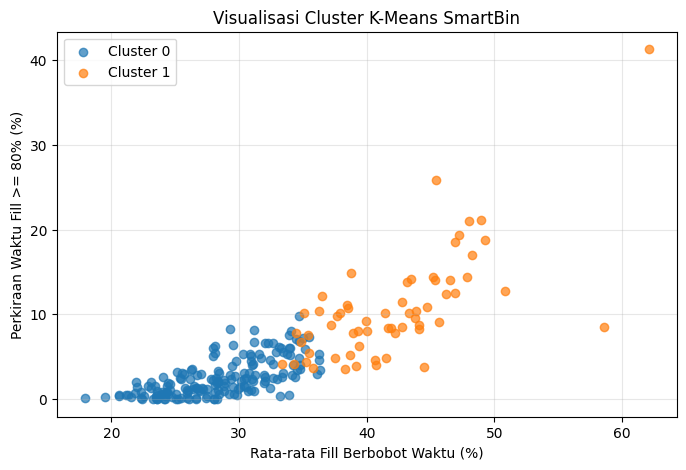

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for cluster in sorted(hasil_cluster["Cluster_KMeans"].unique()):
    data = hasil_cluster[
        hasil_cluster["Cluster_KMeans"] == cluster
    ]

    plt.scatter(
        data["Rata_rata_Fill_Waktu"],
        data["Persen_Waktu_GE80"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Rata-rata Fill Berbobot Waktu (%)")
plt.ylabel("Perkiraan Waktu Fill >= 80% (%)")
plt.title("Visualisasi Cluster K-Means SmartBin")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

evaluasi_akhir = pd.DataFrame([
    {
        "Algoritma": "K-Means",
        "Silhouette_Score": 0.5079,
        "Jumlah_Cluster": 2,
        "Jumlah_Noise": 0,
        "Ukuran_Cluster": "174 : 61",
        "Stabilitas": "Stabil pada 5 pengujian"
    },
    {
        "Algoritma": "K-Medoids",
        "Silhouette_Score": 0.5192,
        "Jumlah_Cluster": 2,
        "Jumlah_Noise": 0,
        "Ukuran_Cluster": "179 : 56",
        "Stabilitas": "4/5 pengujian identik"
    },
    {
        "Algoritma": "DBSCAN",
        "Silhouette_Score": 0.5372,
        "Jumlah_Cluster": 2,
        "Jumlah_Noise": 13,
        "Ukuran_Cluster": "218 : 4",
        "Stabilitas": "Belum diuji"
    }
])

display(evaluasi_akhir)


,Algoritma,Silhouette_Score,Jumlah_Cluster,Jumlah_Noise,Ukuran_Cluster,Stabilitas
0,K-Means,0.5079,2,0,174 : 61,Stabil pada 5 pengujian
1,K-Medoids,0.5192,2,0,179 : 56,4/5 pengujian identik
2,DBSCAN,0.5372,2,13,218 : 4,Belum diuji


In [ ]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
import numpy as np

# Hasil awal sebagai acuan
label_dbscan_awal = DBSCAN(
    eps=0.5,
    min_samples=3
).fit_predict(X_scaled)

# Uji konsistensi setelah urutan data diacak
hasil_stabilitas_dbscan = []

for seed in [0, 10, 21, 42, 100]:
    rng = np.random.RandomState(seed)
    urutan = rng.permutation(len(X_scaled))

    label_acak = DBSCAN(
        eps=0.5,
        min_samples=3
    ).fit_predict(X_scaled[urutan])

    # Kembalikan label ke urutan data awal
    label_kembali = np.empty_like(label_acak)
    label_kembali[urutan] = label_acak

    ari = adjusted_rand_score(
        label_dbscan_awal,
        label_kembali
    )

    hasil_stabilitas_dbscan.append({
        "Seed": seed,
        "ARI": ari
    })

display(hasil_stabilitas_dbscan)


[{'Seed': 0, 'ARI': 1.0},
 {'Seed': 10, 'ARI': 1.0},
 {'Seed': 21, 'ARI': 1.0},
 {'Seed': 42, 'ARI': 1.0},
 {'Seed': 100, 'ARI': 1.0}]

In [ ]:

# Ringkasan karakteristik cluster K-Means
ringkasan = (
    hasil_cluster
    .groupby("Cluster_KMeans")
    .agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Waktu_GE80=("Persen_Waktu_GE80", "mean"),
        Waktu_LE20=("Persen_Waktu_LE20", "mean")
    )
    .round(2)
)

# Tambahkan persentase jumlah kontainer per cluster
ringkasan["Persentase_Kontainer"] = (
    ringkasan["Jumlah_Kontainer"]
    / len(hasil_cluster) * 100
).round(2)

display(ringkasan)


,Jumlah_Kontainer,Rata_rata_Fill,Waktu_GE80,Waktu_LE20,Persentase_Kontainer
Cluster_KMeans,,,,,
0,174,28.52,2.56,40.42,74.04
1,61,42.08,10.70,26.15,25.96


In [ ]:

# Tabel silang cluster K-Means dan K-Medoids
tabel_kesesuaian = pd.crosstab(
    hasil_cluster["Cluster_KMeans"],
    hasil_cluster["Cluster_KMedoids"],
    rownames=["K-Means"],
    colnames=["K-Medoids"]
)

display(tabel_kesesuaian)

# Persentase kesesuaian berdasarkan ARI
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    hasil_cluster["Cluster_KMeans"],
    hasil_cluster["Cluster_KMedoids"]
)

print("Adjusted Rand Index (ARI):", round(ari, 4))


K-Medoids,0,1
K-Means,,
0,0,174
1,56,5


Adjusted Rand Index (ARI): 0.9108


In [ ]:

print("Kolom dataset historis:")
print(df_bersih.columns.tolist())

print("\nContoh data:")
display(df_bersih.head())

print("\nJumlah Container_ID unik:")
print(df_bersih["Container_ID"].nunique())


Kolom dataset historis:
['Container_ID', 'Date', 'Fill', 'Bulan']

Contoh data:


,Container_ID,Date,Fill,Bulan
0,1000,2021-01-09 12:39:00,0.0,2021-01
1,1000,2021-01-16 11:30:00,100.0,2021-01
2,1000,2021-01-16 12:28:00,40.0,2021-01
3,1000,2021-01-16 13:28:00,40.0,2021-01
4,1000,2021-01-17 12:34:00,40.0,2021-01



Jumlah Container_ID unik:
484


In [ ]:

# Rata-rata Fill per bulan untuk setiap Container_ID
ringkasan_bulanan = (
    df_bersih
    .groupby(["Bulan", "Container_ID"])
    .agg(
        Rata_rata_Fill=("Fill", "mean"),
        Jumlah_Pengamatan=("Fill", "count")
    )
    .reset_index()
)

# Ringkasan seluruh kontainer per bulan
ringkasan_bulanan_global = (
    ringkasan_bulanan
    .groupby("Bulan")
    .agg(
        Jumlah_Kontainer=("Container_ID", "nunique"),
        Rata_rata_Fill=("Rata_rata_Fill", "mean"),
        Total_Pengamatan=("Jumlah_Pengamatan", "sum")
    )
    .round(2)
)

display(ringkasan_bulanan_global.tail(12))


,Jumlah_Kontainer,Rata_rata_Fill,Total_Pengamatan
Bulan,,,
2022-11,416,32.15,18483
2022-12,408,34.37,19762
2023-01,421,33.41,19595
2023-02,427,33.90,18812
2023-03,430,33.50,21206
2023-04,429,34.59,21518
2023-05,434,34.94,23539
2023-06,469,36.87,36863
2023-07,475,39.19,51397


In [ ]:

from sklearn.cluster import KMeans
import pandas as pd

# Membentuk 3 kelompok
km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
fitur_kandidat["Cluster_KMeans_3"] = km3.fit_predict(X_scaled)

# Melihat jumlah data setiap kelompok
print("Jumlah data setiap cluster:")
print(fitur_kandidat["Cluster_KMeans_3"].value_counts().sort_index())

# Melihat karakteristik setiap kelompok
hasil_km3 = fitur_kandidat.groupby("Cluster_KMeans_3").agg(
    Jumlah_Kontainer=("Container_ID", "count"),
    Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
    Persen_GE80=("Persen_Waktu_GE80", "mean"),
    Persen_LE20=("Persen_Waktu_LE20", "mean")
).round(2)

display(hasil_km3)


Jumlah data setiap cluster:
Cluster_KMeans_3
0    101
1     34
2    100
Name: count, dtype: int64


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster_KMeans_3,,,,
0,101,33.64,4.68,33.35
1,34,45.81,13.51,23.45
2,100,25.74,1.67,44.63


In [ ]:

from sklearn.metrics import silhouette_score

silhouette_km3 = silhouette_score(X_scaled, fitur_kandidat["Cluster_KMeans_3"])

print(f"Silhouette Score K-Means (3 cluster): {silhouette_km3:.4f}")


Silhouette Score K-Means (3 cluster): 0.3997


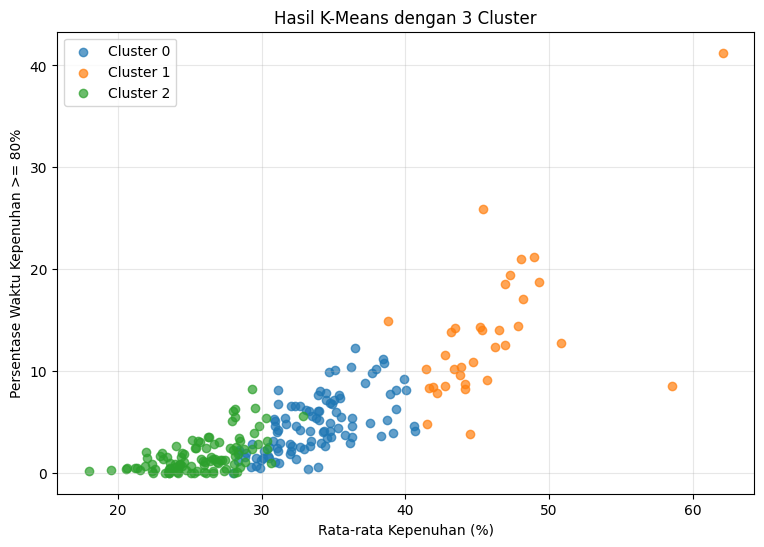

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for cluster in sorted(fitur_kandidat["Cluster_KMeans_3"].unique()):
    data = fitur_kandidat[
        fitur_kandidat["Cluster_KMeans_3"] == cluster
    ]

    plt.scatter(
        data["Rata_rata_Fill_Waktu"],
        data["Persen_Waktu_GE80"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Rata-rata Kepenuhan (%)")
plt.ylabel("Persentase Waktu Kepenuhan >= 80%")
plt.title("Hasil K-Means dengan 3 Cluster")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [ ]:

# Ringkasan karakteristik 3 cluster
ringkasan = fitur_kandidat.groupby("Cluster_KMeans_3").agg(
    Jumlah_Kontainer=("Container_ID", "count"),
    Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
    Persen_GE80=("Persen_Waktu_GE80", "mean"),
    Persen_LE20=("Persen_Waktu_LE20", "mean")
).round(2)

# Urutkan cluster berdasarkan rata-rata kepenuhan
ringkasan = ringkasan.sort_values("Rata_rata_Fill")

display(ringkasan)


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster_KMeans_3,,,,
2,100,25.74,1.67,44.63
0,101,33.64,4.68,33.35
1,34,45.81,13.51,23.45


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

label_awal = fitur_kandidat["Cluster_KMeans_3"].to_numpy()
hasil_stabilitas = []

for seed in [0, 10, 21, 42, 100]:
    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10
    )
    label_baru = model.fit_predict(X_scaled)

    ari = adjusted_rand_score(label_awal, label_baru)

    hasil_stabilitas.append({
        "Random_State": seed,
        "ARI": round(ari, 4)
    })

display(pd.DataFrame(hasil_stabilitas))


,Random_State,ARI
0,0,1.0
1,10,1.0
2,21,1.0
3,42,1.0
4,100,1.0


In [ ]:

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
import pandas as pd
import numpy as np

# Data dan fitur yang sama untuk semua algoritma
X_eval = X_scaled

hasil_perbandingan = []

# 1. K-Means: dipaksa membentuk 3 cluster
km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
label_km = km3.fit_predict(X_eval)

hasil_perbandingan.append({
    "Algoritma": "K-Means",
    "Jumlah_Cluster": len(set(label_km)),
    "Jumlah_Noise": 0,
    "Silhouette": round(silhouette_score(X_eval, label_km), 4)
})

# 2. K-Medoids: dipaksa membentuk 3 cluster
kmed3 = KMedoids(
    n_clusters=3,
    metric="euclidean",
    init="k-medoids++",
    random_state=42
)
label_kmed = kmed3.fit_predict(X_eval)

hasil_perbandingan.append({
    "Algoritma": "K-Medoids",
    "Jumlah_Cluster": len(set(label_kmed)),
    "Jumlah_Noise": 0,
    "Silhouette": round(silhouette_score(X_eval, label_kmed), 4)
})

# 3. DBSCAN: parameter awal yang sudah diuji
db = DBSCAN(eps=0.5, min_samples=3)
label_db = db.fit_predict(X_eval)

cluster_db = set(label_db) - {-1}
mask_db = label_db != -1

if len(cluster_db) >= 2 and mask_db.sum() > len(cluster_db):
    skor_db = silhouette_score(X_eval[mask_db], label_db[mask_db])
else:
    skor_db = np.nan

hasil_perbandingan.append({
    "Algoritma": "DBSCAN",
    "Jumlah_Cluster": len(cluster_db),
    "Jumlah_Noise": int((label_db == -1).sum()),
    "Silhouette": round(skor_db, 4) if not np.isnan(skor_db) else None
})

display(pd.DataFrame(hasil_perbandingan))



,Algoritma,Jumlah_Cluster,Jumlah_Noise,Silhouette
0,K-Means,3,0,0.3997
1,K-Medoids,3,0,0.4006
2,DBSCAN,2,13,0.5372


In [ ]:

from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
import pandas as pd

# K-Means dengan 3 cluster
km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
label_km3 = km3.fit_predict(X_scaled)

# K-Medoids dengan 3 cluster
kmed3 = KMedoids(
    n_clusters=3,
    metric="euclidean",
    init="k-medoids++",
    random_state=42
)
label_kmed3 = kmed3.fit_predict(X_scaled)

# Buat salinan agar hasil sebelumnya tetap aman
hasil_data = fitur_kandidat.copy()
hasil_data["Cluster_KMeans"] = label_km3
hasil_data["Cluster_KMedoids"] = label_kmed3

# Ringkasan karakteristik tiap algoritma
for nama, kolom in [
    ("K-Means", "Cluster_KMeans"),
    ("K-Medoids", "Cluster_KMedoids")
]:
    print(f"\n=== {nama} ===")
    ringkasan = hasil_data.groupby(kolom).agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Persen_GE80=("Persen_Waktu_GE80", "mean"),
        Persen_LE20=("Persen_Waktu_LE20", "mean")
    ).round(2)
    display(ringkasan)



=== K-Means ===


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster_KMeans,,,,
0,101,33.64,4.68,33.35
1,34,45.81,13.51,23.45
2,100,25.74,1.67,44.63



=== K-Medoids ===


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster_KMedoids,,,,
0,33,45.75,14.00,24.09
1,108,26.01,1.63,44.01
2,94,34.15,4.89,32.77


In [ ]:

from sklearn.metrics import adjusted_rand_score

hasil_stabilitas_kmed = []

# Pembanding menggunakan hasil K-Medoids seed 42
label_awal_kmed = KMedoids(
    n_clusters=3,
    metric="euclidean",
    init="k-medoids++",
    random_state=42
).fit_predict(X_scaled)

for seed in [0, 10, 21, 42, 100]:
    model = KMedoids(
        n_clusters=3,
        metric="euclidean",
        init="k-medoids++",
        random_state=seed
    )
    label_baru = model.fit_predict(X_scaled)

    hasil_stabilitas_kmed.append({
        "Random_State": seed,
        "ARI": round(
            adjusted_rand_score(label_awal_kmed, label_baru), 4
        )
    })

display(pd.DataFrame(hasil_stabilitas_kmed))


,Random_State,ARI
0,0,0.9715
1,10,0.9715
2,21,0.9715
3,42,1.0000
4,100,0.4630


EVALUASI ALGORITMA AI SMARTBIN
Jumlah kontainer : 235
Jumlah fitur     : 3
Fitur yang dipakai: ['Rata_rata_Fill_Waktu', 'Persen_Waktu_GE80', 'Persen_Waktu_LE20']

1. PERBANDINGAN ALGORITMA


,Algoritma,Jumlah_Cluster,Jumlah_Noise,Silhouette_Score
0,K-Means,3,0,0.3997
1,K-Medoids,3,0,0.4006
2,DBSCAN,2,13,0.5372



2. KARAKTERISTIK CLUSTER K-MEANS


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster,,,,
2,100,25.74,1.67,44.63
0,101,33.64,4.68,33.35
1,34,45.81,13.51,23.45



2. KARAKTERISTIK CLUSTER K-MEDOIDS


,Jumlah_Kontainer,Rata_rata_Fill,Persen_GE80,Persen_LE20
Cluster,,,,
1,108,26.01,1.63,44.01
2,94,34.15,4.89,32.77
0,33,45.75,14.00,24.09


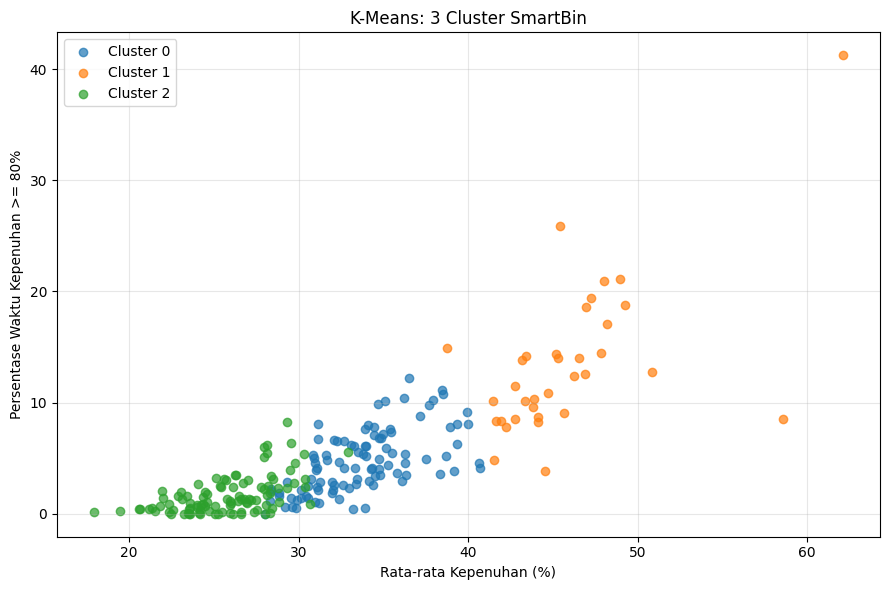


3. UJI KESTABILAN MODEL


,Algoritma,Random_State,ARI
0,K-Means,0,1.0000
1,K-Means,10,1.0000
2,K-Means,21,1.0000
3,K-Means,42,1.0000
4,K-Means,100,1.0000
5,K-Medoids,0,0.9715
6,K-Medoids,10,0.9715
7,K-Medoids,21,0.9715
8,K-Medoids,42,1.0000
9,K-Medoids,100,0.4630



Ringkasan kestabilan:


,mean,min,max
Algoritma,,,
K-Means,1.0000,1.000,1.0
K-Medoids,0.8755,0.463,1.0



4. PENGUJIAN JUMLAH CLUSTER K-MEANS


,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.5079,335.16
1,3,0.3997,221.95
2,4,0.3646,175.76
3,5,0.3303,145.92
4,6,0.3509,121.26
5,7,0.3470,99.11
6,8,0.3245,89.60


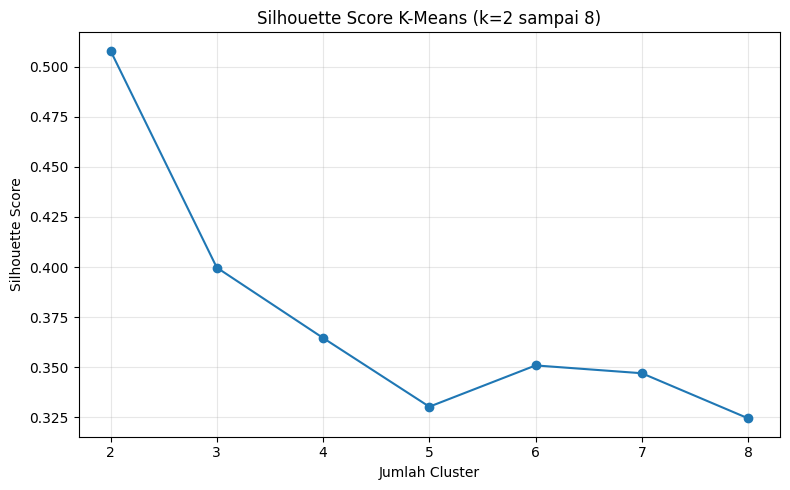


5. KESIMPULAN PENGUJIAN
-----------------------------------------------------------------
K-Means dan K-Medoids diuji dengan 3 cluster.
DBSCAN menentukan cluster berdasarkan kepadatan data.
Silhouette DBSCAN dihitung tanpa data noise.
ARI mengukur kesamaan hasil clustering, bukan akurasi.
K-Means dapat dipertimbangkan sebagai kandidat utama,
tetapi keputusan akhir perlu mempertimbangkan seluruh hasil.

CATATAN:
Pengujian ini menggunakan data historis per kontainer,
belum memvalidasi pengelompokan lokasi kampus.


In [ ]:

# ============================================================
# EVALUASI ALGORITMA AI SMARTBIN
# K-Means vs K-Medoids vs DBSCAN
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn_extra.cluster import KMedoids

# ------------------------------------------------------------
# 1. PERSIAPAN DATA
# ------------------------------------------------------------
X_eval = X_scaled

print("=" * 65)
print("EVALUASI ALGORITMA AI SMARTBIN")
print("=" * 65)
print(f"Jumlah kontainer : {X_eval.shape[0]}")
print(f"Jumlah fitur     : {X_eval.shape[1]}")
print(f"Fitur yang dipakai: {kolom_fitur}")

# ------------------------------------------------------------
# 2. PENGUJIAN TIGA ALGORITMA
# ------------------------------------------------------------

# K-Means: 3 cluster
km = KMeans(n_clusters=3, random_state=42, n_init=10)
label_km = km.fit_predict(X_eval)

# K-Medoids: 3 cluster
kmed = KMedoids(
    n_clusters=3, metric="euclidean",
    init="k-medoids++", random_state=42
)
label_kmed = kmed.fit_predict(X_eval)

# DBSCAN: parameter eksperimen sebelumnya
db = DBSCAN(eps=0.5, min_samples=3)
label_db = db.fit_predict(X_eval)

def evaluasi(nama, labels, X):
    cluster = set(labels) - {-1}
    mask = labels != -1
    n_cluster = len(cluster)
    n_noise = int((labels == -1).sum())

    if n_cluster >= 2 and mask.sum() > n_cluster:
        skor = silhouette_score(X[mask], labels[mask])
    else:
        skor = np.nan

    return {
        "Algoritma": nama,
        "Jumlah_Cluster": n_cluster,
        "Jumlah_Noise": n_noise,
        "Silhouette_Score": round(skor, 4)
            if not np.isnan(skor) else None
    }

tabel_evaluasi = pd.DataFrame([
    evaluasi("K-Means", label_km, X_eval),
    evaluasi("K-Medoids", label_kmed, X_eval),
    evaluasi("DBSCAN", label_db, X_eval)
])

print("\n1. PERBANDINGAN ALGORITMA")
display(tabel_evaluasi)

# ------------------------------------------------------------
# 3. KARAKTERISTIK CLUSTER K-MEANS DAN K-MEDOIDS
# ------------------------------------------------------------

def ringkasan_cluster(labels, nama):
    data = fitur_kandidat.copy()
    data["Cluster"] = labels

    hasil = data.groupby("Cluster").agg(
        Jumlah_Kontainer=("Container_ID", "count"),
        Rata_rata_Fill=("Rata_rata_Fill_Waktu", "mean"),
        Persen_GE80=("Persen_Waktu_GE80", "mean"),
        Persen_LE20=("Persen_Waktu_LE20", "mean")
    ).round(2)

    hasil = hasil.sort_values("Rata_rata_Fill")

    print(f"\n2. KARAKTERISTIK CLUSTER {nama}")
    display(hasil)
    return hasil

ringkasan_km = ringkasan_cluster(label_km, "K-MEANS")
ringkasan_kmed = ringkasan_cluster(label_kmed, "K-MEDOIDS")

# ------------------------------------------------------------
# 4. GRAFIK K-MEANS TIGA CLUSTER
# ------------------------------------------------------------

data_plot = fitur_kandidat.copy()
data_plot["Cluster"] = label_km

plt.figure(figsize=(9, 6))

for c in sorted(data_plot["Cluster"].unique()):
    subset = data_plot[data_plot["Cluster"] == c]
    plt.scatter(
        subset["Rata_rata_Fill_Waktu"],
        subset["Persen_Waktu_GE80"],
        label=f"Cluster {c}",
        alpha=0.7
    )

plt.xlabel("Rata-rata Kepenuhan (%)")
plt.ylabel("Persentase Waktu Kepenuhan >= 80%")
plt.title("K-Means: 3 Cluster SmartBin")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. UJI KESTABILAN K-MEANS DAN K-MEDOIDS
# ------------------------------------------------------------

hasil_stabilitas = []

for nama, model_acuan, label_acuan in [
    ("K-Means", km, label_km),
    ("K-Medoids", kmed, label_kmed)
]:
    for seed in [0, 10, 21, 42, 100]:
        if nama == "K-Means":
            model = KMeans(
                n_clusters=3, random_state=seed, n_init=10
            )
        else:
            model = KMedoids(
                n_clusters=3, metric="euclidean",
                init="k-medoids++", random_state=seed
            )

        label_baru = model.fit_predict(X_eval)
        ari = adjusted_rand_score(label_acuan, label_baru)

        hasil_stabilitas.append({
            "Algoritma": nama,
            "Random_State": seed,
            "ARI": round(ari, 4)
        })

tabel_stabilitas = pd.DataFrame(hasil_stabilitas)

print("\n3. UJI KESTABILAN MODEL")
display(tabel_stabilitas)

print("\nRingkasan kestabilan:")
display(
    tabel_stabilitas.groupby("Algoritma")["ARI"]
    .agg(["mean", "min", "max"])
    .round(4)
)

# ------------------------------------------------------------
# 6. UJI JUMLAH CLUSTER K-MEANS (K=2 SAMPAI K=8)
# ------------------------------------------------------------

hasil_k = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k, random_state=42, n_init=10
    )
    labels = model.fit_predict(X_eval)

    hasil_k.append({
        "Jumlah_Cluster": k,
        "Silhouette_Score": round(
            silhouette_score(X_eval, labels), 4
        ),
        "Inertia": round(model.inertia_, 2)
    })

tabel_k = pd.DataFrame(hasil_k)

print("\n4. PENGUJIAN JUMLAH CLUSTER K-MEANS")
display(tabel_k)

plt.figure(figsize=(8, 5))
plt.plot(
    tabel_k["Jumlah_Cluster"],
    tabel_k["Silhouette_Score"],
    marker="o"
)
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score K-Means (k=2 sampai 8)")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. KESIMPULAN OTOMATIS BERDASARKAN HASIL UJI
# ------------------------------------------------------------

print("\n5. KESIMPULAN PENGUJIAN")
print("-" * 65)
print("K-Means dan K-Medoids diuji dengan 3 cluster.")
print("DBSCAN menentukan cluster berdasarkan kepadatan data.")
print("Silhouette DBSCAN dihitung tanpa data noise.")
print("ARI mengukur kesamaan hasil clustering, bukan akurasi.")
print("K-Means dapat dipertimbangkan sebagai kandidat utama,")
print("tetapi keputusan akhir perlu mempertimbangkan seluruh hasil.")
print("\nCATATAN:")
print("Pengujian ini menggunakan data historis per kontainer,")
print("belum memvalidasi pengelompokan lokasi kampus.")


In [ ]:
# Simpan dataset bersih
df_bersih.to_csv(
    "smartbin_dataset_bersih.csv",
    index=False
)

# Unduh file ke komputer
from google.colab import files
files.download("smartbin_dataset_bersih.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Dataset bersih tersedia:", "df_bersih" in globals())

if "df_bersih" in globals():
    print("Jumlah baris dan kolom:", df_bersih.shape)
    display(df_bersih.head())

Dataset bersih tersedia: True
Jumlah baris dan kolom: (788590, 4)


,Container_ID,Date,Fill,Bulan
0,1000,2021-01-09 12:39:00,0.0,2021-01
1,1000,2021-01-16 11:30:00,100.0,2021-01
2,1000,2021-01-16 12:28:00,40.0,2021-01
3,1000,2021-01-16 13:28:00,40.0,2021-01
4,1000,2021-01-17 12:34:00,40.0,2021-01


In [ ]:
variabel_penting = [
    "fitur_kandidat",
    "X",
    "X_scaled",
    "kmeans",
    "kmedoids",
    "dbscan"
]

for nama in variabel_penting:
    print(f"{nama}: {'Tersedia' if nama in globals() else 'Belum tersedia'}")

fitur_kandidat: Tersedia
X: Tersedia
X_scaled: Tersedia
kmeans: Belum tersedia
kmedoids: Belum tersedia
dbscan: Tersedia


In [ ]:
print("Variabel terkait clustering:")

for nama in list(globals().keys()):
    if any(kata in nama.lower() for kata in [
        "kmeans", "kmedoids", "medoids",
        "cluster", "silhouette", "labels"
    ]):
        objek = globals()[nama]
        if not callable(objek):
            print(nama, "| tipe:", type(objek).__name__)

Variabel terkait clustering:
hasil_kmeans | tipe: DataFrame
df_kmeans | tipe: DataFrame
kmeans_4 | tipe: KMeans
cluster3 | tipe: DataFrame
hasil_kmedoids | tipe: DataFrame
hasil_cluster | tipe: DataFrame
hasil_stabilitas_kmedoids | tipe: list
cluster_unik | tipe: set
jumlah_cluster | tipe: int
labels | tipe: ndarray
cluster_valid | tipe: set
hasil_dbscan_cluster | tipe: DataFrame
cluster_dbscan | tipe: set
daftar_kmeans | tipe: DataFrame
cluster | tipe: int32
silhouette_km3 | tipe: float64
cluster_db | tipe: set


In [ ]:
print("=== HASIL K-MEANS ===")
print("Ukuran data:", hasil_kmeans.shape)
display(hasil_kmeans.head())

print("\n=== HASIL K-MEDOIDS ===")
print("Ukuran data:", hasil_kmedoids.shape)
display(hasil_kmedoids.head())

print("\n=== HASIL DBSCAN ===")
print("Ukuran data:", hasil_dbscan_cluster.shape)
display(hasil_dbscan_cluster.head())

print("\n=== EVALUASI K-MEANS 3 CLUSTER ===")
print("Silhouette Score:", silhouette_km3)

=== HASIL K-MEANS ===
Ukuran data: (7, 3)


,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.507876,335.164077
1,3,0.399725,221.953623
2,4,0.364573,175.758670
3,5,0.330256,145.917388
4,6,0.350878,121.259066



=== HASIL K-MEDOIDS ===
Ukuran data: (7, 3)


,Jumlah_Cluster,Silhouette_Score,Inertia
0,2,0.519211,240.808770
1,3,0.400603,191.834386
2,4,0.397931,184.799540
3,5,0.374068,172.298663
4,6,0.342038,154.684858



=== HASIL DBSCAN ===
Ukuran data: (235, 6)


,Container_ID,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Total_Durasi_Valid_Jam,Cluster_DBSCAN
0,1000,49.278446,18.763328,21.434128,6620.050000,0
4,10077,28.145981,1.659683,42.614878,6865.266667,1
5,10078,22.584403,0.340400,48.422593,8039.566667,1
6,10079,24.169754,0.363979,45.437606,8720.750000,1
8,10083,25.054079,0.670123,40.952900,8646.416667,1



=== EVALUASI K-MEANS 3 CLUSTER ===
Silhouette Score: 0.39972458774224845


In [ ]:
print("=== DATASET HISTORIS BERSIH ===")
df_bersih.info()

print("\n=== DATASET FITUR AI ===")
fitur_kandidat.info()

=== DATASET HISTORIS BERSIH ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 788590 entries, 0 to 788589
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Container_ID  788590 non-null  object        
 1   Date          788590 non-null  datetime64[ns]
 2   Fill          788590 non-null  float64       
 3   Bulan         788590 non-null  period[M]     
dtypes: datetime64[ns](1), float64(1), object(1), period[M](1)
memory usage: 24.1+ MB

=== DATASET FITUR AI ===
<class 'pandas.core.frame.DataFrame'>
Index: 235 entries, 0 to 375
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Container_ID            235 non-null    object 
 1   Rata_rata_Fill_Waktu    235 non-null    float64
 2   Persen_Waktu_GE80       235 non-null    float64
 3   Persen_Waktu_LE20       235 non-null    float64
 4   Total_Durasi_Valid

In [ ]:
print("Tanggal awal:", df_bersih["Date"].min())
print("Tanggal akhir:", df_bersih["Date"].max())
print("Jumlah Container_ID unik:", df_bersih["Container_ID"].nunique())

Tanggal awal: 2021-01-01 00:01:00
Tanggal akhir: 2023-10-23 20:41:00
Jumlah Container_ID unik: 484


In [ ]:

import pandas as pd
import numpy as np

np.random.seed(42)

jumlah_data = 30

df_simulasi = pd.DataFrame({
    "Container_ID": [f"SIM-{i:03d}" for i in range(1, jumlah_data + 1)],
    "Date": pd.date_range(
        start="2026-01-01 08:00:00",
        periods=jumlah_data,
        freq="h"
    ),
    "Fill": np.random.uniform(0, 100, jumlah_data).round(2),
    "Sumber_Data": "Simulasi"
})

df_simulasi["Bulan"] = df_simulasi["Date"].dt.to_period("M")

print("Jumlah data simulasi:", len(df_simulasi))
display(df_simulasi.head(10))


Jumlah data simulasi: 30


,Container_ID,Date,Fill,Sumber_Data,Bulan
0,SIM-001,2026-01-01 08:00:00,37.45,Simulasi,2026-01
1,SIM-002,2026-01-01 09:00:00,95.07,Simulasi,2026-01
2,SIM-003,2026-01-01 10:00:00,73.20,Simulasi,2026-01
3,SIM-004,2026-01-01 11:00:00,59.87,Simulasi,2026-01
4,SIM-005,2026-01-01 12:00:00,15.60,Simulasi,2026-01
5,SIM-006,2026-01-01 13:00:00,15.60,Simulasi,2026-01
6,SIM-007,2026-01-01 14:00:00,5.81,Simulasi,2026-01
7,SIM-008,2026-01-01 15:00:00,86.62,Simulasi,2026-01
8,SIM-009,2026-01-01 16:00:00,60.11,Simulasi,2026-01
9,SIM-010,2026-01-01 17:00:00,70.81,Simulasi,2026-01


In [ ]:

# Periksa nilai kosong dan duplikat pada dataset historis
print("=== DATA HISTORIS ===")
print("Nilai kosong per kolom:")
print(df_bersih.isnull().sum())

print("\nJumlah baris duplikat seluruh kolom:",
      df_bersih.duplicated().sum())

print("Duplikat berdasarkan Container_ID dan Date:",
      df_bersih.duplicated(
          subset=["Container_ID", "Date"]
      ).sum())


# Periksa dataset simulasi
print("\n=== DATA SIMULASI ===")
print("Nilai kosong per kolom:")
print(df_simulasi.isnull().sum())

print("Duplikat berdasarkan Container_ID dan Date:",
      df_simulasi.duplicated(
          subset=["Container_ID", "Date"]
      ).sum())


=== DATA HISTORIS ===
Nilai kosong per kolom:
Container_ID    0
Date            0
Fill            0
Bulan           0
dtype: int64

Jumlah baris duplikat seluruh kolom: 0
Duplikat berdasarkan Container_ID dan Date: 0

=== DATA SIMULASI ===
Nilai kosong per kolom:
Container_ID    0
Date            0
Fill            0
Sumber_Data     0
Bulan           0
dtype: int64
Duplikat berdasarkan Container_ID dan Date: 0


In [ ]:

kolom_eksplorasi = [
    "Rata_rata_Fill_Waktu",
    "Persen_Waktu_GE80",
    "Persen_Waktu_LE20",
    "Total_Durasi_Valid_Jam"
]

print("=== STATISTIK DESKRIPTIF FITUR AI ===")
display(fitur_kandidat[kolom_eksplorasi].describe().round(2))

print("\n=== JUMLAH DATA ===")
print("Jumlah objek:", len(fitur_kandidat))

print("\n=== PEMERIKSAAN NILAI KOSONG ===")
print(fitur_kandidat[kolom_eksplorasi].isnull().sum())


=== STATISTIK DESKRIPTIF FITUR AI ===


,Rata_rata_Fill_Waktu,Persen_Waktu_GE80,Persen_Waktu_LE20,Total_Durasi_Valid_Jam
count,235.00,235.00,235.00,235.00
mean,32.04,4.67,36.72,7999.64
std,7.47,5.16,9.27,1311.73
min,17.95,0.00,1.10,4373.37
25%,26.53,1.15,30.81,8133.34
50%,30.83,3.01,36.63,8675.75
75%,35.43,6.58,42.87,8717.63
max,62.09,41.25,57.91,8758.22



=== JUMLAH DATA ===
Jumlah objek: 235

=== PEMERIKSAAN NILAI KOSONG ===
Rata_rata_Fill_Waktu      0
Persen_Waktu_GE80         0
Persen_Waktu_LE20         0
Total_Durasi_Valid_Jam    0
dtype: int64


In [ ]:

print("Distribusi cluster DBSCAN:")
print(hasil_dbscan_cluster["Cluster_DBSCAN"].value_counts().sort_index())

jumlah_noise = (
    hasil_dbscan_cluster["Cluster_DBSCAN"] == -1
).sum()

jumlah_cluster_dbscan = (
    hasil_dbscan_cluster.loc[
        hasil_dbscan_cluster["Cluster_DBSCAN"] != -1,
        "Cluster_DBSCAN"
    ].nunique()
)

print("\nJumlah cluster (tanpa noise):", jumlah_cluster_dbscan)
print("Jumlah data noise:", jumlah_noise)


Distribusi cluster DBSCAN:
Cluster_DBSCAN
-1     13
 0      4
 1    218
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 2
Jumlah data noise: 13
